In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf
from statsmodels.tsa.filters.hp_filter import hpfilter

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.simplefilter("ignore", SparseEfficiencyWarning)

from Functions import run_multistart, plot_predictive_density, compute_bimodality_series, plot_bimodality, plot_bimodality_and_series, shock_analysis, plot_predictive_density_simple, plot_predictive_density_ax, plot_bimodality_and_series_2
from MLE_Predictive_Density import neg_loglik_mar11_cauchy, neg_loglik_marx_cauchy, neg_loglik_student_mar, neg_loglik_student_marx, mar_cauchy_pred_density, marx_cauchy_pred_density, mar_studentt_pred_density, marx_studentt_pred_density


In [2]:
# Linear Trend of Volatility Scaling Function 

def linear_vol_scale(price, window=12):
    """
    Scale price using a linear trend on smoothed log-variance.
    """

    price = price.dropna()


    # -------------------------
    # Smooth variance 
    # -------------------------
    var_smooth = price.pow(2).ewm(span=window, adjust=False).mean()

    # -------------------------
    # Clean NaNs
    # -------------------------
    var_smooth = var_smooth.dropna()

    # -------------------------
    # Fit linear trend on LOG variance 
    # -------------------------
    log_var = np.log(var_smooth.values + 1e-8)

    t = np.arange(len(log_var))
    slope, intercept = np.polyfit(t, log_var, 1)

    log_var_trend = intercept + slope * t

    # Back to variance (guaranteed positive)
    var_trend = np.exp(log_var_trend)

    var_trend = pd.Series(var_trend, index=var_smooth.index)

    # -------------------------
    # Volatility (safe sqrt)
    # -------------------------
    vol = np.sqrt(var_trend)

    # safety floor (extra robustness)
    vol = vol.clip(lower=1e-8)

    return vol


### Import WTI and detrend series with HP filter + linear trend of the volatility scaling

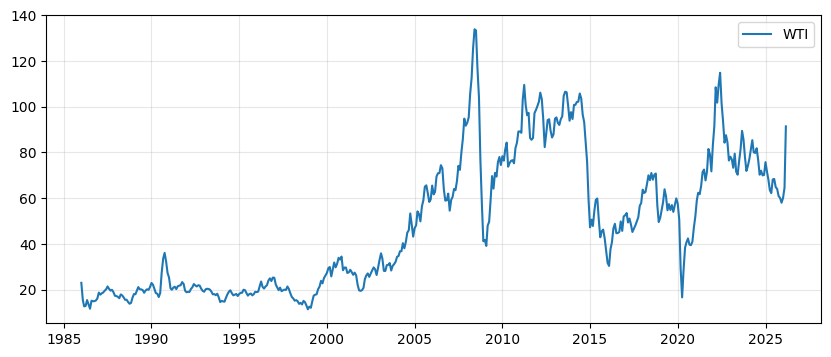

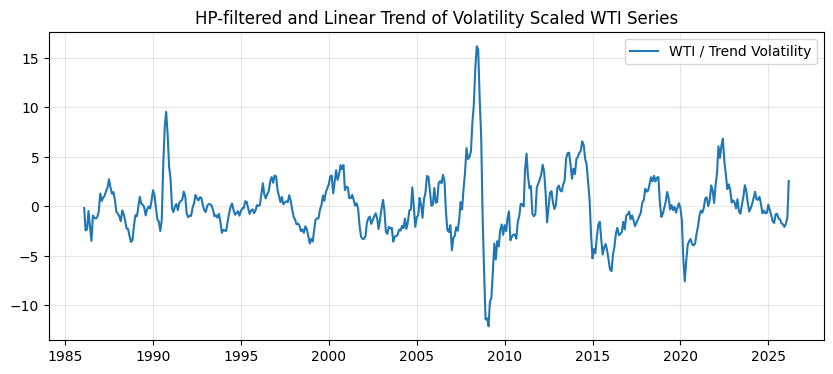

In [3]:
# -------------------------
# WTI DATA
# -------------------------
df_wti = pd.read_csv("MCOILWTICO.csv", parse_dates=["observation_date"])
df_wti = df_wti.dropna().set_index("observation_date")

# HP filter
cycle, trend = hpfilter(df_wti["MCOILWTICO"], lamb=129600)

df_wti["wti_cycle"] = cycle
df_wti["wti_trend"] = trend

# Compute differences and linear trend volatility estimation
wti_diff = (df_wti["wti_cycle"]).diff()
wti_vol = linear_vol_scale(wti_diff)

df_wti["wti_scaled_cycle"] = df_wti["wti_cycle"]/wti_vol


# -------------------------
# PLOTS
# -------------------------

# Plot original series
plt.figure(figsize=(10,4))
plt.plot(df_wti.index, df_wti["MCOILWTICO"], label="WTI")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(10,4))
plt.plot(df_wti["wti_scaled_cycle"], label="WTI / Trend Volatility")
plt.legend()
plt.grid(alpha=0.3)
plt.title("HP-filtered and Linear Trend of Volatility Scaled WTI Series")
plt.show()

### Extract Data for Exogeous Variables

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77499/389981700.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


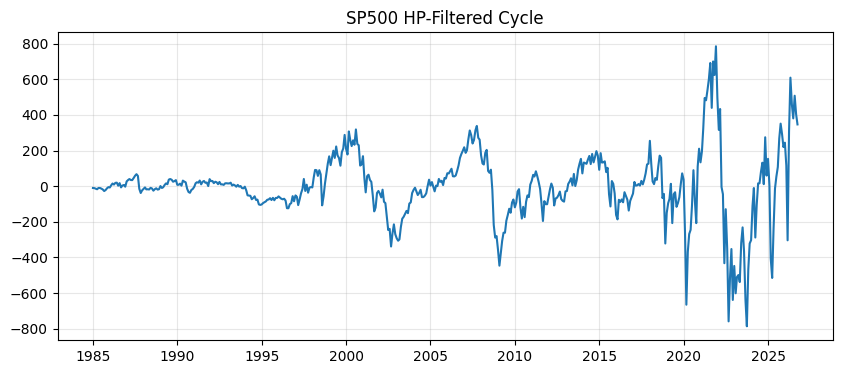

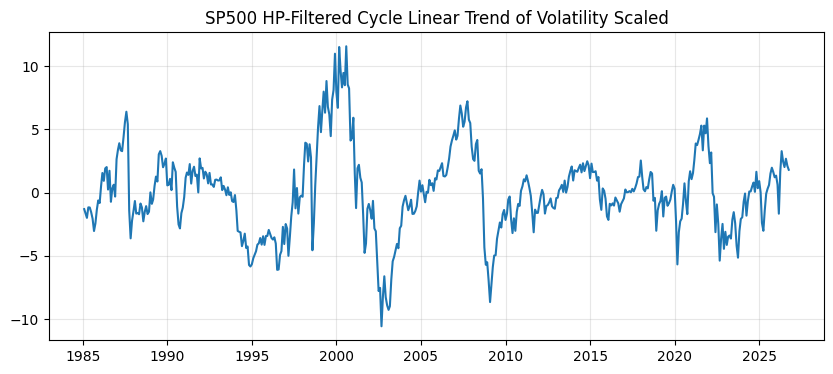

In [4]:
# -------------------------
# S&P 500
# -------------------------
sp500_original = yf.download("^GSPC", start="1950-01-01", interval="1mo")["Close"]
sp500_original = sp500_original.squeeze().dropna()

# HP filter
sp500_cycle, trend = hpfilter(sp500_original, lamb=129600)

sp500_diff = (sp500_cycle).diff().dropna()
sp500_sigma = linear_vol_scale(sp500_diff)

sp500= sp500_cycle/sp500_sigma


plt.figure(figsize=(10,4))
plt.plot(sp500_cycle)
plt.title("SP500 HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(sp500)
plt.title("SP500 HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77499/904516455.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
[*********************100%***********************]  1 of 1 completed


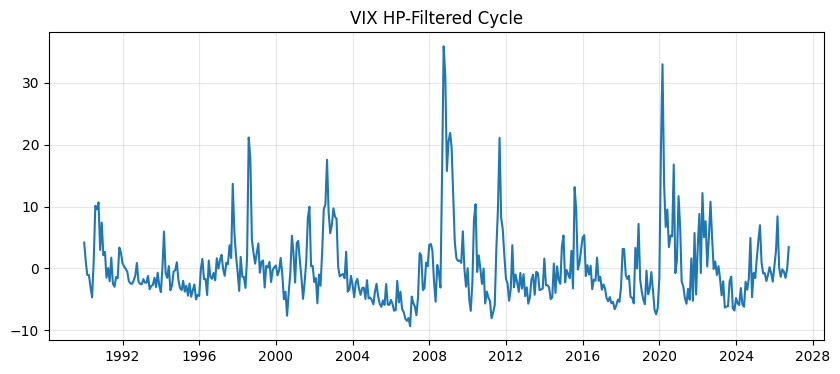

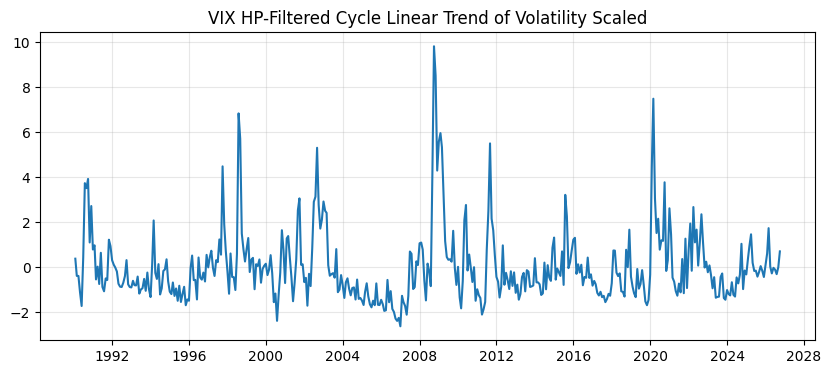

In [5]:
# -------------------------
# VIX
# -------------------------
vix_original = yf.download("^VIX", start="1985-01-01", interval="1mo")["Close"]
vix_original = vix_original.dropna()

# -------------------------
# HP Filter 
# -------------------------
vix_cycle, trend = hpfilter(vix_original, lamb=129600)

vix_diff = (vix_cycle).diff().dropna()
vix_sigma = linear_vol_scale(vix_diff)

vix= vix_cycle/vix_sigma


plt.figure(figsize=(10,4))
plt.plot(vix_cycle)
plt.title("VIX HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(vix)
plt.title("VIX HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

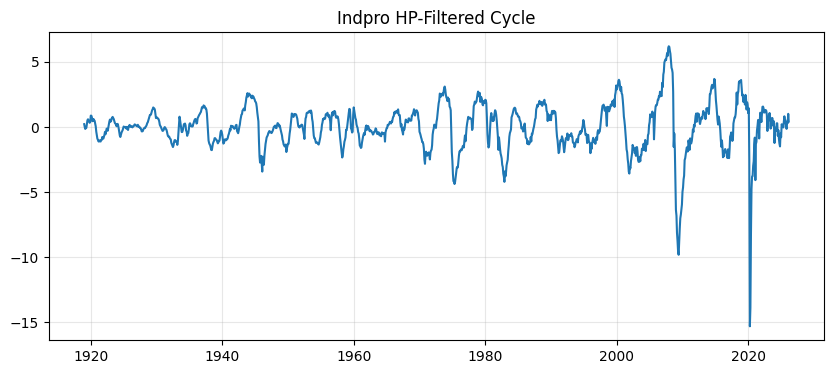

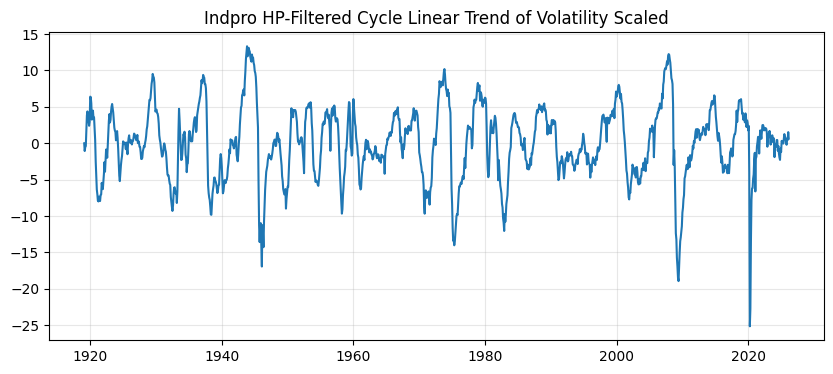

In [6]:
# -------------------------
# INDUSTRIAL PRODUCTION
# -------------------------
indpro_original = pd.read_csv("INDPRO.csv", parse_dates=["observation_date"])
indpro_original = indpro_original.dropna().set_index("observation_date")


# -------------------------
# HP Filter 
# -------------------------
indpro_cycle, trend = hpfilter(indpro_original, lamb=129600)

indpro_diff = (indpro_cycle).diff().dropna()
indpro_sigma = linear_vol_scale(indpro_diff)

indpro = indpro_cycle/indpro_sigma


plt.figure(figsize=(10,4))
plt.plot(indpro_cycle)
plt.title("Indpro HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(indpro)
plt.title("Indpro HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

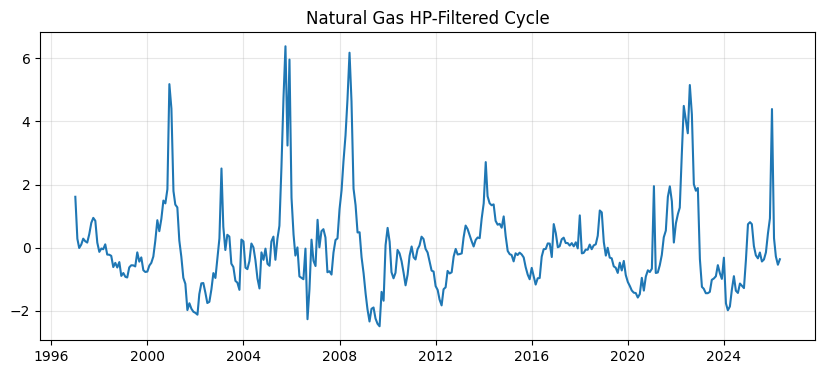

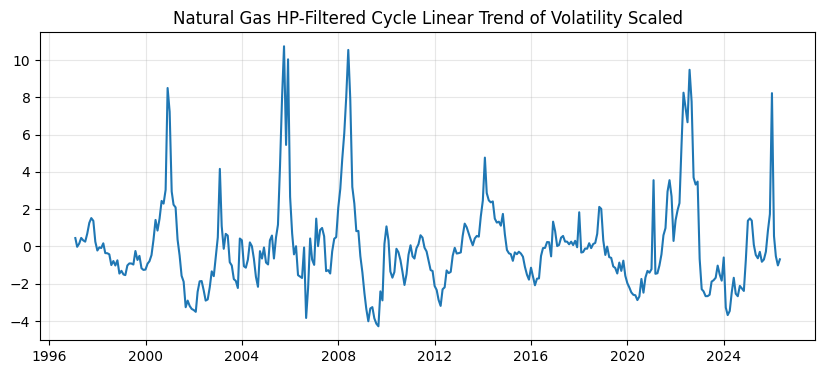

In [7]:
# -------------------------
# Natural Gas
# -------------------------
df_ngas = pd.read_csv("MHHNGSP.csv", parse_dates=["observation_date"])
df_ngas = df_ngas.dropna().set_index("observation_date")


# HP filter
ngas_cycle, ngas_trend = hpfilter(df_ngas["MHHNGSP"], lamb=129600)

ngas_diff = (ngas_cycle).diff().dropna()
ngas_sigma = linear_vol_scale(ngas_diff)

ngas= ngas_cycle/ngas_sigma


plt.figure(figsize=(10,4))
plt.plot(ngas_cycle)
plt.title("Natural Gas HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(ngas)
plt.title("Natural Gas HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

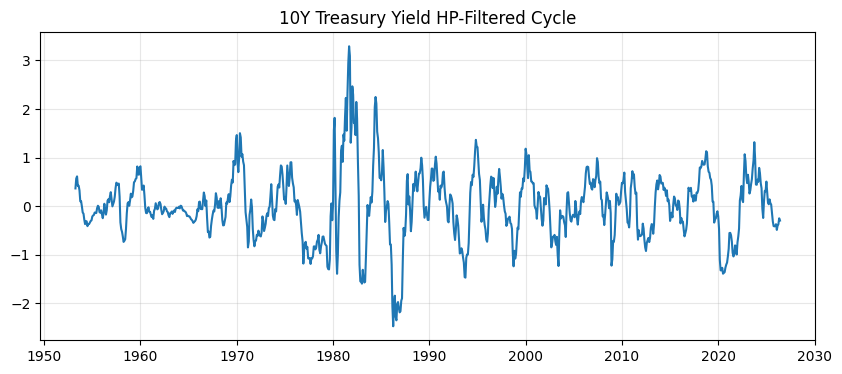

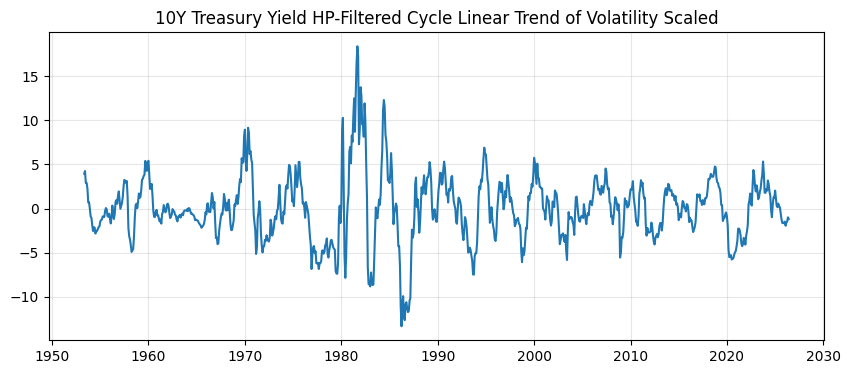

In [8]:
# -------------------------
# 10 Year Treasury Yield
# -------------------------
df_10y_treasury = pd.read_csv("GS10.csv", parse_dates=["observation_date"])
df_10y_treasury = df_10y_treasury.dropna().set_index("observation_date")


# HP filter
treasury_10y_cycle , trend = hpfilter(df_10y_treasury["GS10"], lamb=129600)

treasury_10y_diff = (treasury_10y_cycle).diff().dropna()
treasury_10y_sigma = linear_vol_scale(treasury_10y_diff)

treasury_10y= treasury_10y_cycle/treasury_10y_sigma


plt.figure(figsize=(10,4))
plt.plot(treasury_10y_cycle)
plt.title("10Y Treasury Yield HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(treasury_10y)
plt.title("10Y Treasury Yield HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

/var/folders/3y/fngh4g1x6r1b8dh7v7mbhp9m0000gn/T/ipykernel_77499/3610332454.py:4: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,495,496,497,498,499,500,501,502,503,504,505,506,507,508,509,510,511,512,513,514,515,516,517,518,519,520,521,522,523,524,525,526,527,528,529,530,531,532,533,534,535,536,537,538,539,540,541,542,543,544,545,546,547,548,549,550,551,552,553,554,555,556,557,558,559,560,561,562,563,564,565,566,567,568,569,570,571,572,573,574,575,576,577,578,579,580,581,582,583,584,585,586,587,588,589,590,591,592,593,594,595,596,597,598,599,600,601,602,603,604,605,606,607,608,609,610,611,612,613,614,615,616,617,618,619,620,621,622,623) have mixed types. Specify dtype op

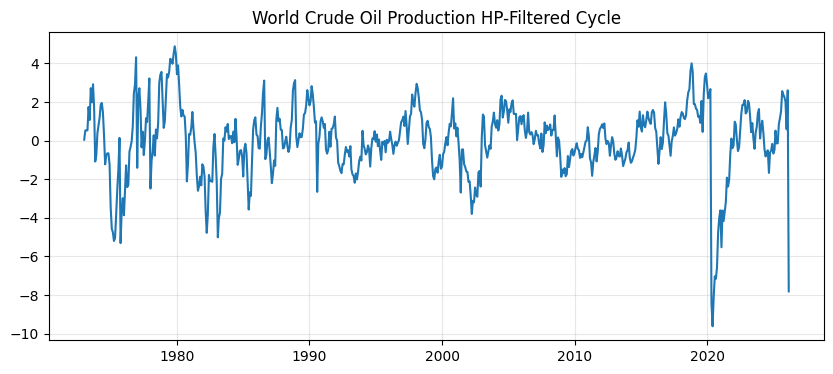

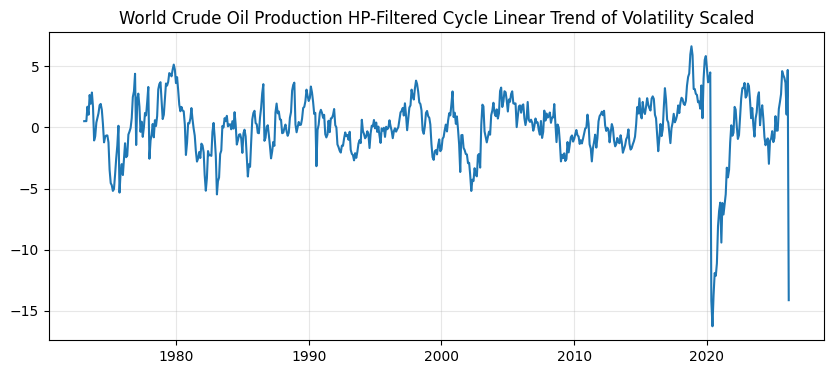

In [9]:
# -------------------------
# World Crude Oil Production
# -------------------------
df_oil = pd.read_csv(
    "World Crude Oil Production.csv",
    skiprows=1
)

# Select the World crude oil production row
world_crude = df_oil[
    df_oil["API"].str.contains("WORL", na=False) &
    df_oil.iloc[:,1].str.contains("Crude oil including lease condensate", na=False)
]


# Keep only the monthly data (drop metadata columns)
oil_series = world_crude.iloc[0, 2:]

# Convert the column names (YYYYMM) to dates
oil_series.index = pd.to_datetime(oil_series.index, format="%b %Y")

# Convert values to numeric
oil_series = pd.to_numeric(oil_series, errors="coerce").dropna()

# HP filter

oil_series=0.001*oil_series
world_oil_cycle, oil_trend = hpfilter(oil_series, lamb=129600)

world_oil_diff = (world_oil_cycle).diff().dropna()
world_oil_sigma = linear_vol_scale(world_oil_diff)

world_oil= world_oil_cycle/world_oil_sigma


plt.figure(figsize=(10,4))
plt.plot(world_oil_cycle)
plt.title("World Crude Oil Production HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(world_oil)
plt.title("World Crude Oil Production HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

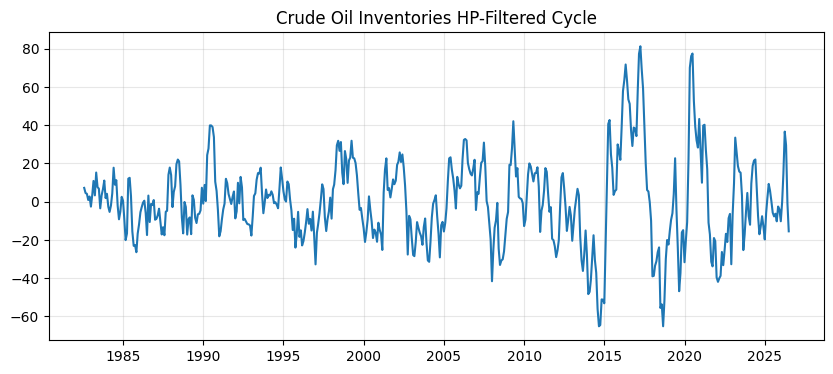

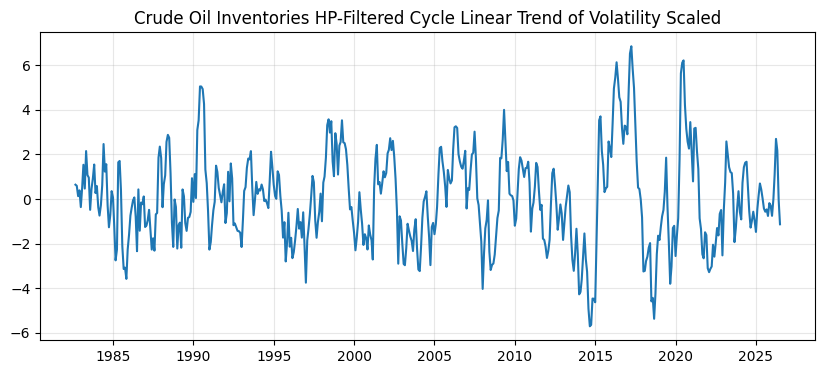

In [10]:
# -------------------------
# Crude Oil Inventories
# -------------------------

df_inv = pd.read_excel(
    "Crude Oil Inventories WEEKLY.xls",
    sheet_name="Data 1",      
    skiprows=2                
)

# Convert dates
df_inv["Date"] = pd.to_datetime(df_inv["Date"])

# Keep the first weekly observation of each month
df_inv = (
    df_inv.sort_values("Date")
          .groupby(df_inv["Date"].dt.to_period("M"), as_index=False)
          .first()
)

# Set dates to the first day of each month
df_inv["Date"] = df_inv["Date"].dt.to_period("M").dt.to_timestamp()

# Set index
df_inv = df_inv.set_index("Date").dropna()

# -------------------------
# HP Filter
# -------------------------
df_inv=0.001*df_inv
crudeoil_inventory_cycle, crudeoil_inventory_trend = hpfilter(
    df_inv["Weekly U.S. Ending Stocks excluding SPR of Crude Oil  (Thousand Barrels)"],  
    lamb=129600
)

crudeoil_inventory_diff = (crudeoil_inventory_cycle).diff().dropna()
crudeoil_inventory_sigma = linear_vol_scale(crudeoil_inventory_diff)

crudeoil_inventory= crudeoil_inventory_cycle/crudeoil_inventory_sigma


plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory_cycle)
plt.title("Crude Oil Inventories HP-Filtered Cycle")
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(10,4))
plt.plot(crudeoil_inventory)
plt.title("Crude Oil Inventories HP-Filtered Cycle Linear Trend of Volatility Scaled")
plt.grid(alpha=0.3)
plt.show()

In [11]:
# Data and Parameters 
df = pd.concat(
    [
        df_wti["wti_scaled_cycle"], sp500, vix, indpro, ngas, treasury_10y, world_oil, crudeoil_inventory
    ],
    axis=1
).dropna()

df.columns = ["wti_scaled_cycle", "sp500", "vix", "indpro", "ngas", "treasury_10y", "world_oil", "crudeoil_inventory"]
df = df.sort_index()

start_date = "1997-02-01"
end_date   = "2026-03-01"

df = df.loc[start_date:end_date].dropna()

y = df["wti_scaled_cycle"].values
X = df[["sp500", "vix", "indpro", "ngas", "treasury_10y", "world_oil",  "crudeoil_inventory"]].values

var = ["sp500", "vix", "indpro", "ngas", "treasury_10y", "world_oil", "crudeoil_inventory"]



print(f"Aligned sample: {len(y)} monthly observations")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")

t1=len(y)-1 # point to calculate predictive density


#Define Grid for all experiments
grid_min=-100
grid_max=100
ngrid=2000
grid = np.linspace(grid_min, grid_max, ngrid)

#Define points where to calculate bimodality for all experiments
min_t = 2
max_t = len(y) 
times = np.arange(min_t, max_t)

#Parameters for effect of exogenous regressors on bimodality 
std=10
values=30

prominence = 0.01

y_limits=(-20, 20)

Aligned sample: 350 monthly observations
Date range: 1997-02-01 to 2026-03-01


In [12]:
import pickle

with open("psy_wti.pkl", "rb") as f:
    psy = pickle.load(f)

----
## MAR(1,1) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -575.1749034440684

Estimated parameters:
phi             =     0.7851 (0.0397)
psi             =     0.3443 (0.0659)
sigma           =     0.5982 (0.0425)

Hessian condition number:
8.346606071522604

Eigenvalues of Hessian:
[1568.33841727  187.90133425  567.68377318]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -575.174903
AIC:            1156.349807
BIC:            1167.906414
R^2:            0.871958

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 6.515016, p-value = 0.0106967
    lag  5: statistic = 19.544728, p-value = 0.00152093
    lag 10: statistic = 23.923496, p-value = 0.00780606
    lag 20: statistic = 35.525498, p-value = 0.0174776

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 46.941146, p-value = 7.31504e-12
    lag  5: st

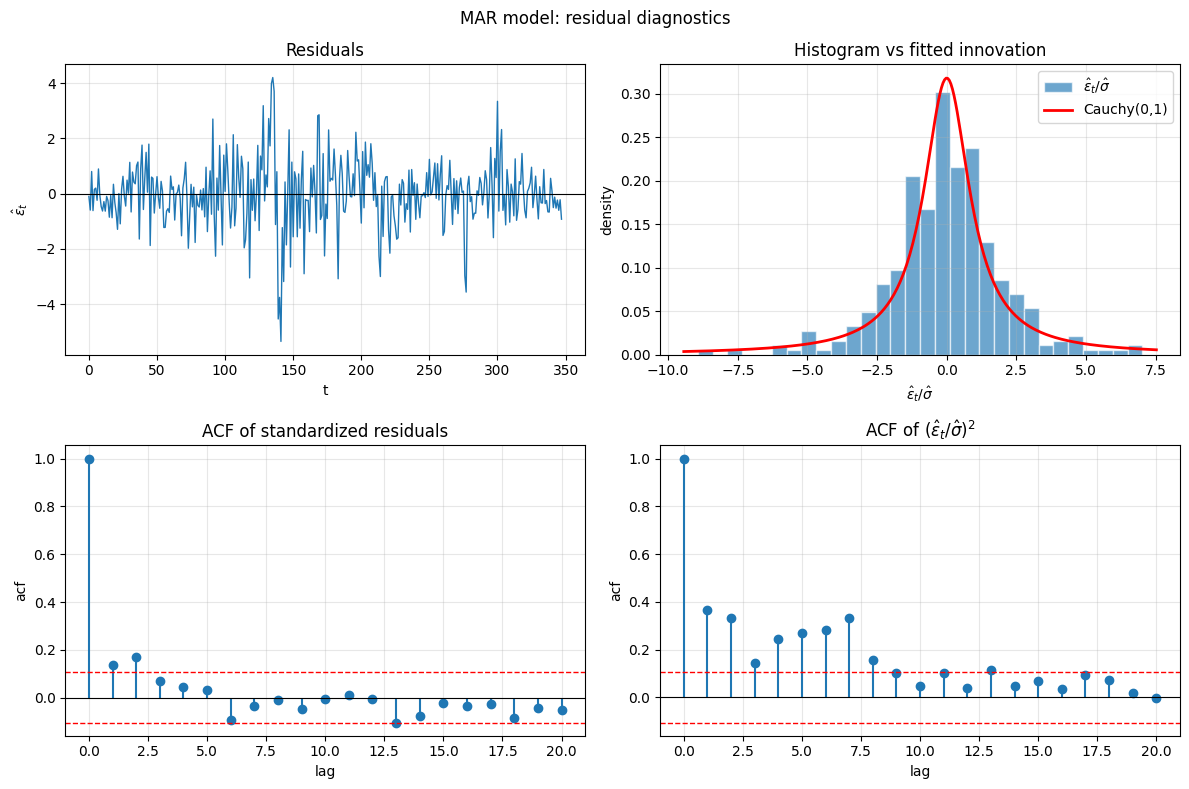

In [13]:
param_names = [ "phi", "psi", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_mar11_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T))^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

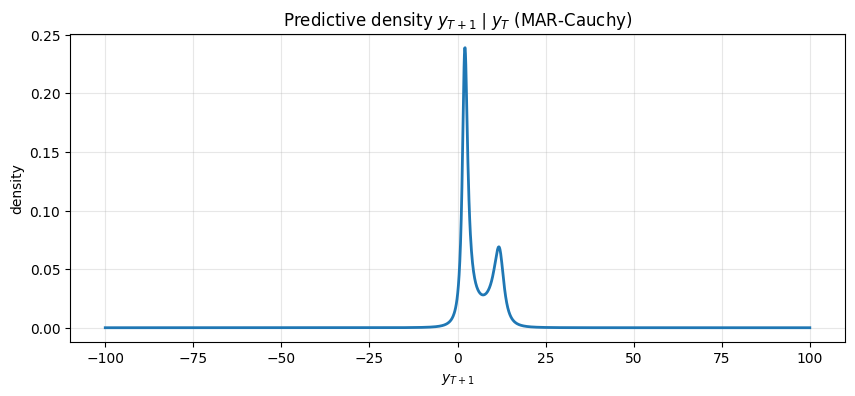

In [14]:
dens = plot_predictive_density(
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR-Cauchy)"
)

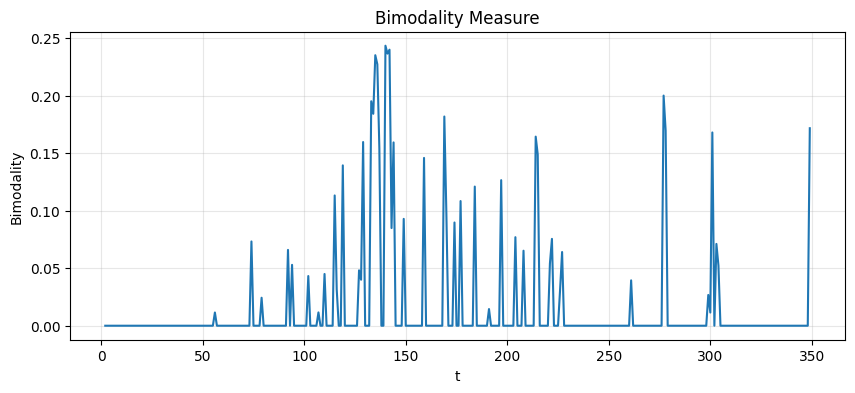

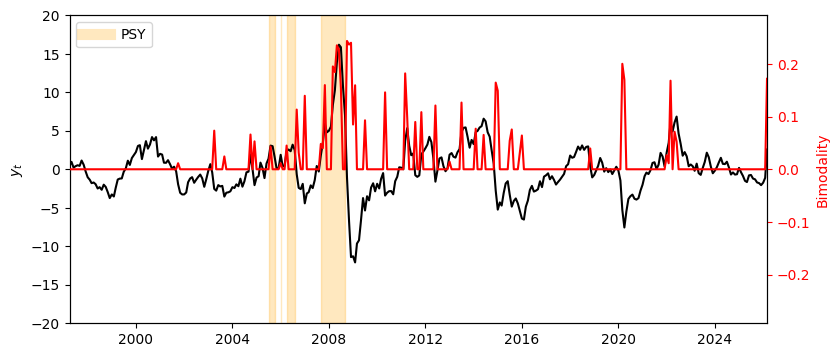

In [15]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_cauchy_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

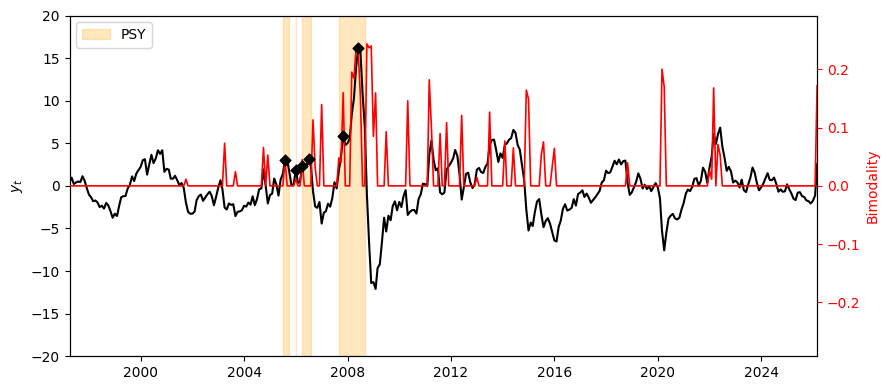

In [16]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 100, 105, 108, 111, 127, 134]
)

### Look at Predictive Density at points of interest

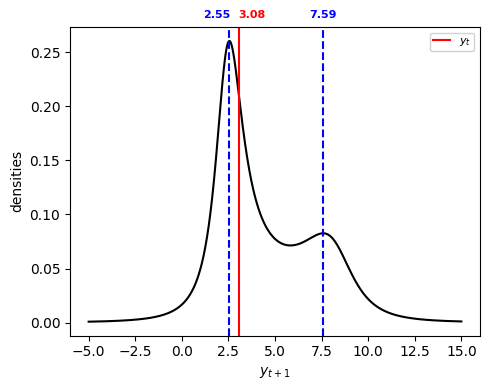

In [17]:
t0 = 102

grid1 = np.linspace(-5, 15, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

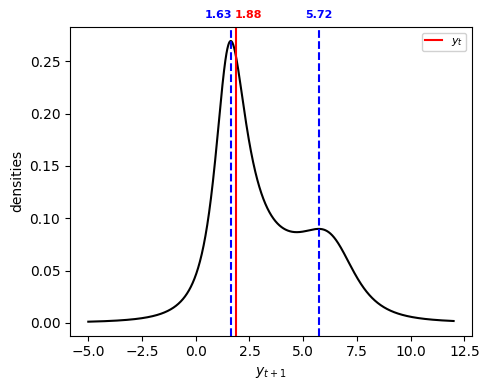

In [18]:
t0 = 107

grid1 = np.linspace(-5, 12, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

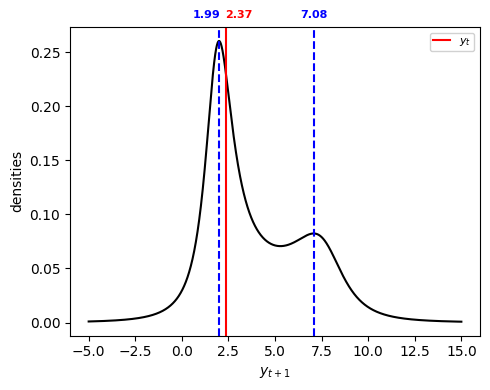

In [19]:
t0 = 110

grid1 = np.linspace(-5, 15, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

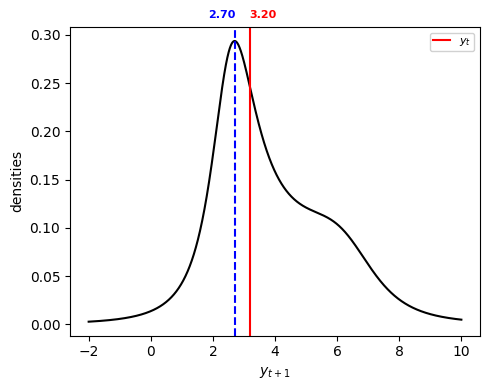

In [20]:
t0 = 113

grid1 = np.linspace(-2, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

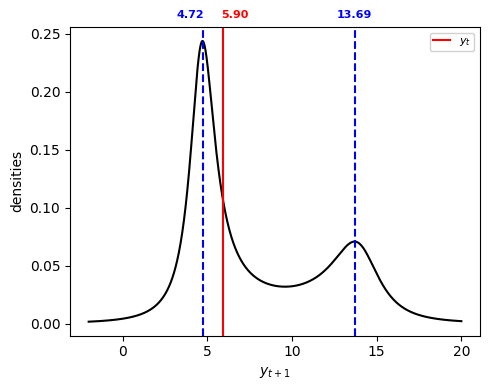

In [21]:
t0 = 129

grid1 = np.linspace(-2, 20, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

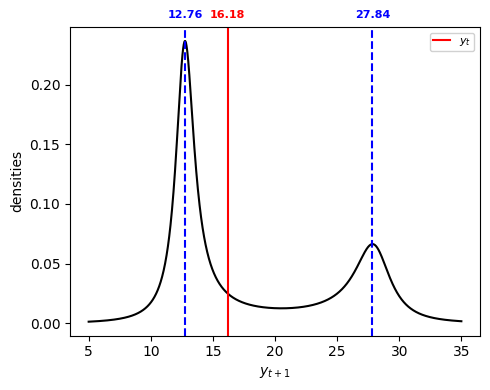

In [22]:
t0 = 136

grid1 = np.linspace(5, 35, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=mar_cauchy_pred_density,
    grid=grid1,
    y=y,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

----
## MARX(1,1,3) with Cauchy Innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma)
=
\sum_{t=2}^{T-1}
\left[
-\log(\pi\sigma)
-
\log\left(
1+\left(\frac{(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t}{\sigma}\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -538.5336857924593

Estimated parameters:
phi             =     0.3947 (0.0422)
psi             =     0.5567 (0.0353)
beta_sp500      =    -0.0528 (0.0168)
beta_vix        =    -0.0911 (0.0338)
beta_indpro     =     0.0843 (0.0169)
beta_ngas_cycle =     0.1277 (0.0267)
beta_treasury_10y =     0.0822 (0.0226)
beta_world_oil_cycle =    -0.1067 (0.0180)
beta_crudeoil_inventory =    -0.1214 (0.0236)
sigma           =     0.5349 (0.0382)

Hessian condition number:
53.32079525745784

Eigenvalues of Hessian:
[19924.32457055  6643.3509625   3687.08900428  2988.33108145
   373.66893112   607.38504793   754.80008062  1304.5317566
  2050.15411625  1671.68091214]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -538.533686
AIC:            1097.067372
BIC:            1135.589396
R^2:            0.896871

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 

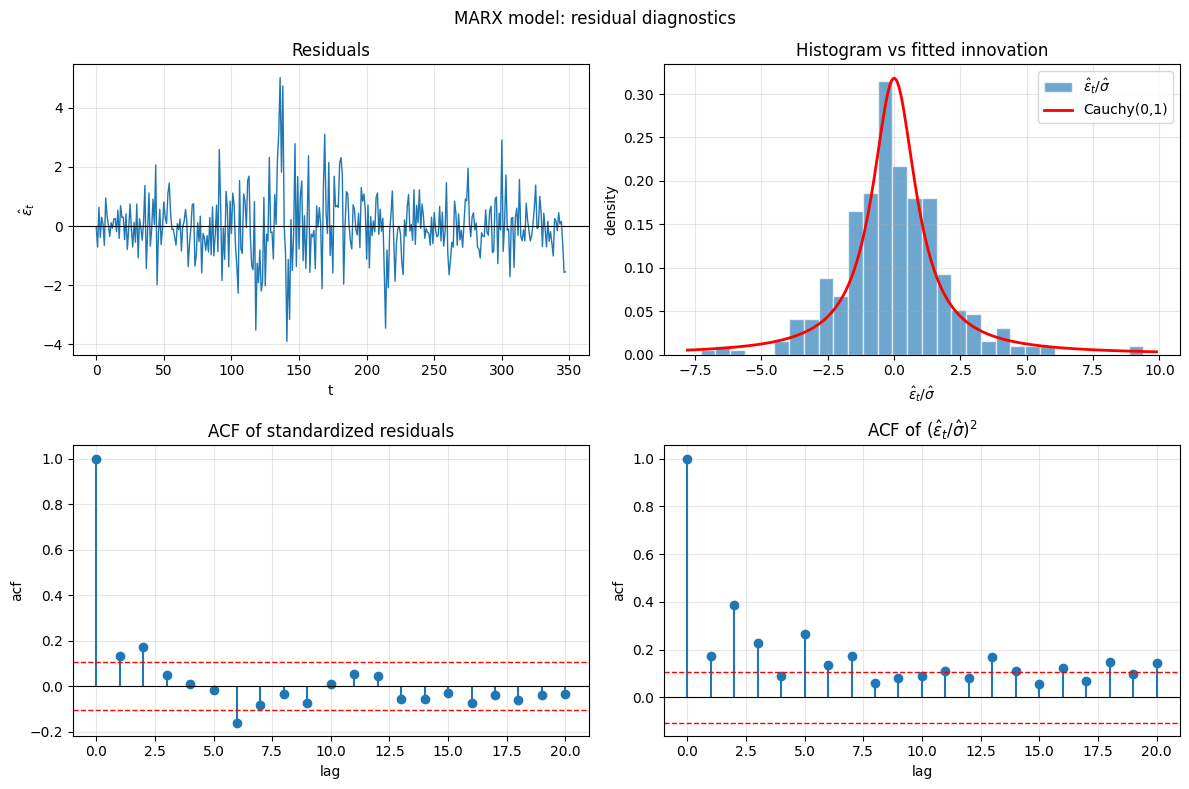

In [23]:
# MARX Cauchy MLE

param_names = [ "phi", "psi", "beta_sp500", "beta_vix", "beta_indpro", "beta_ngas_cycle", "beta_treasury_10y","beta_world_oil_cycle", "beta_crudeoil_inventory", "sigma"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_marx_cauchy,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]

### Predictive Density

$$
f(y_{T+1}\mid y_T, X_T)
=
\frac{1}{\pi \sigma}
\frac{\sigma^2}{(u_T-\psi (y_{T+1}-\phi y_T)- \beta X_T)^2+\sigma^2}
\cdot
\frac{\sigma^2+(1-|\psi|)^2 u_T^2}{\sigma^2+(1-|\psi|)^2 (y_{T+1} - \phi y_T)^2}
$$

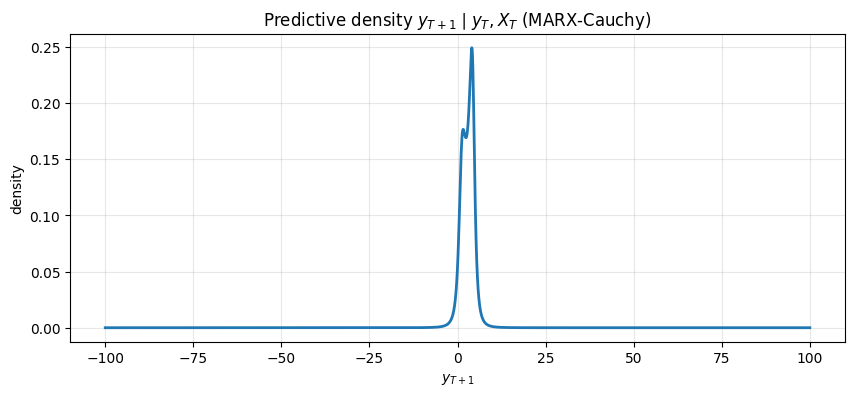

In [24]:
dens = plot_predictive_density(
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX-Cauchy)")

### Bimodality

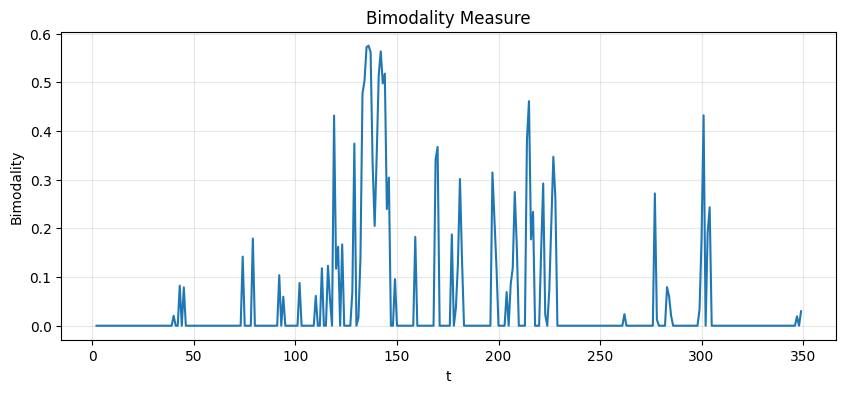

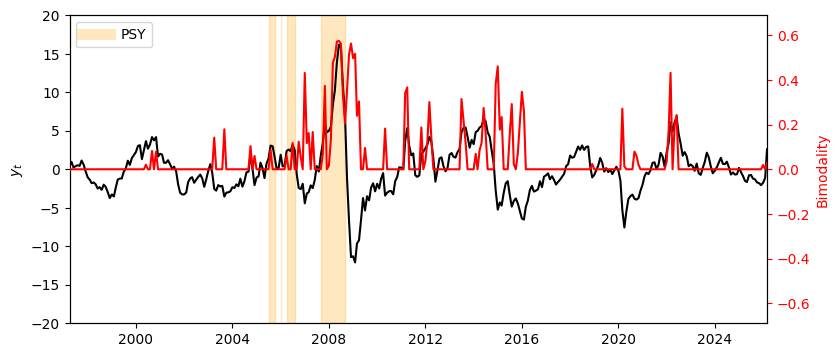

In [25]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_cauchy_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)

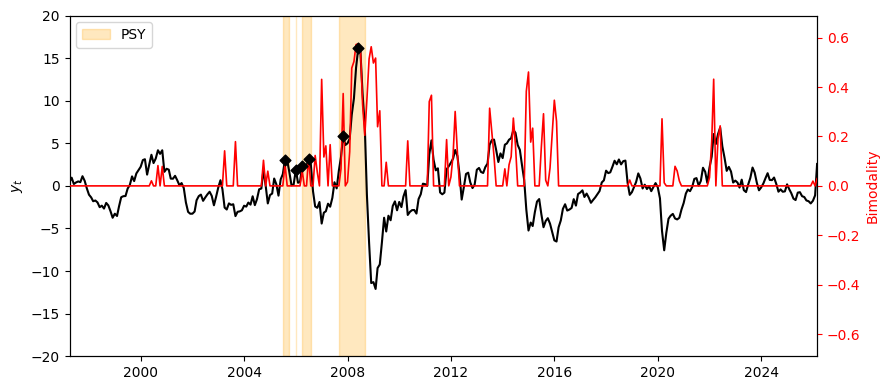

In [26]:
plot_bimodality_and_series_2(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy,
    marker_points=[ 100, 105, 108, 111, 127, 134]
)

### Look at Predictive Density at points of interest

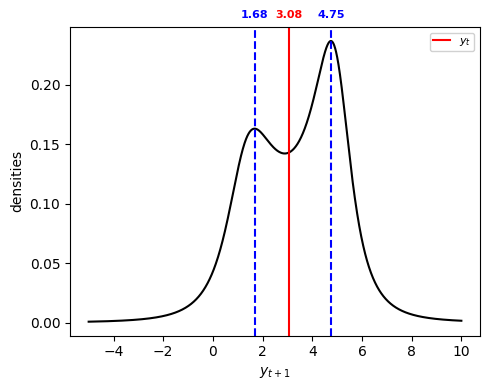

In [27]:
t0 = 102

grid1 = np.linspace(-5, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

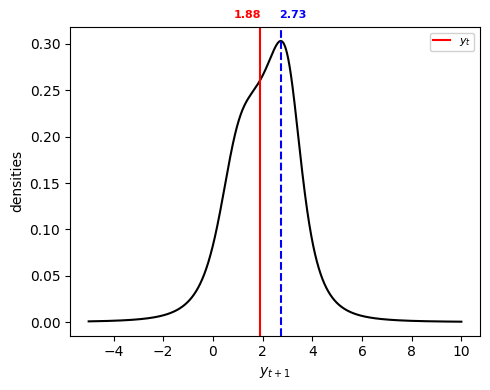

In [28]:
t0 = 107

grid1 = np.linspace(-5, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

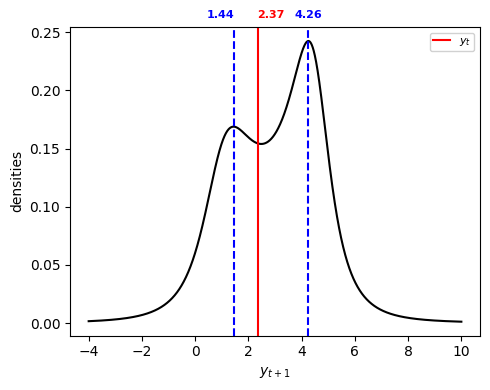

In [29]:
t0 = 110

grid1 = np.linspace(-4, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

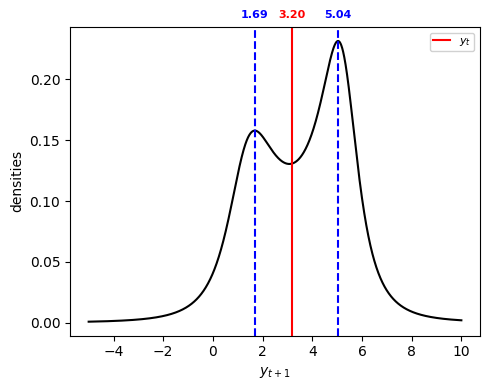

In [30]:
t0 = 113

grid1 = np.linspace(-5, 10, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

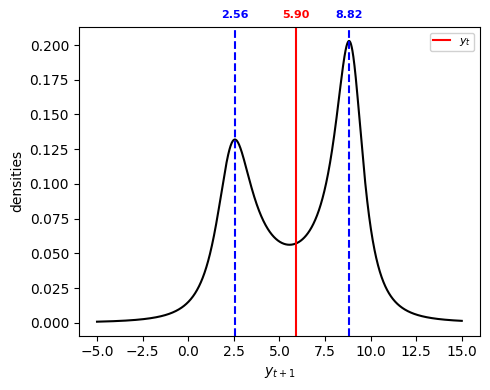

In [31]:
t0 = 129

grid1 = np.linspace(-5, 15, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

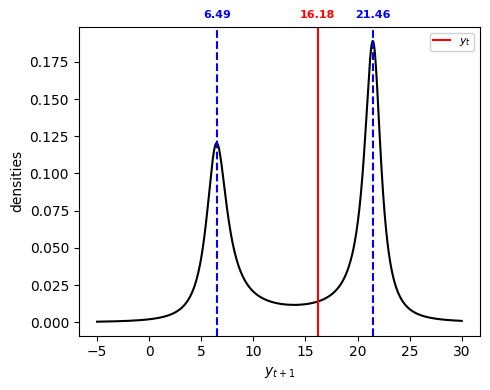

In [32]:
t0 = 136

grid1 = np.linspace(-5, 30, 2000)

fig, ax = plt.subplots(figsize=(5, 4))

plot_predictive_density_ax(
    ax=ax,
    predictive_density_fn=marx_cauchy_pred_density,
    grid=grid1,
    y=y,
    X=X,
    t=t0,
    params=params
    #title=f"{df.index[t0].strftime('%B %Y')}\nbimodality={bimodality_series[t0-2]:.3f}",
)

plt.tight_layout()
plt.show()

### Look at Predictive Density at and around all points where bimodality is not 0

Bimodal times:
[ 40  43  45  74  79  92  94 102 110 113 116 117 119 120 121 123 128 129
 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145 146 149 159
 169 170 177 179 180 181 182 197 198 199 204 206 207 208 209 214 215 216
 217 221 222 223 225 226 227 228 262 277 278 283 284 285 299 300 301 303
 304 347 349]


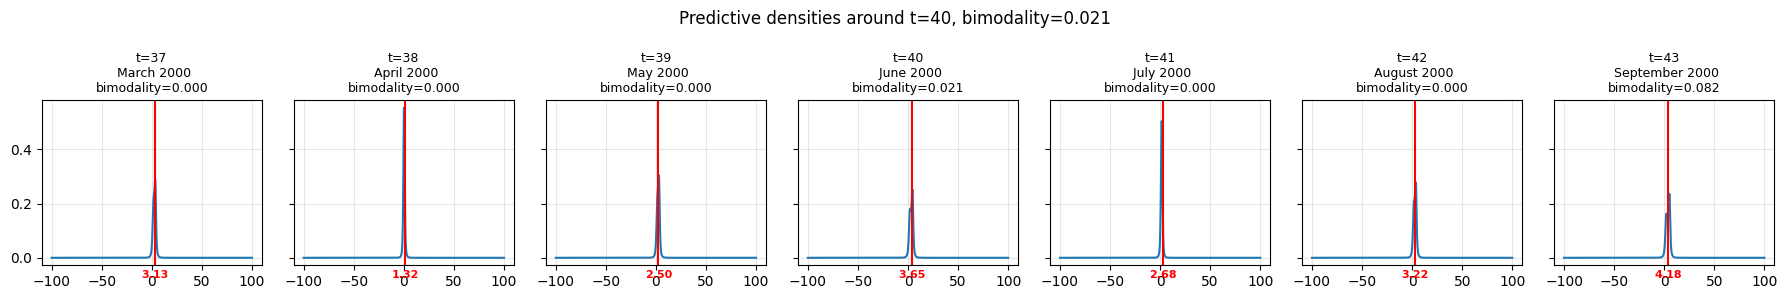

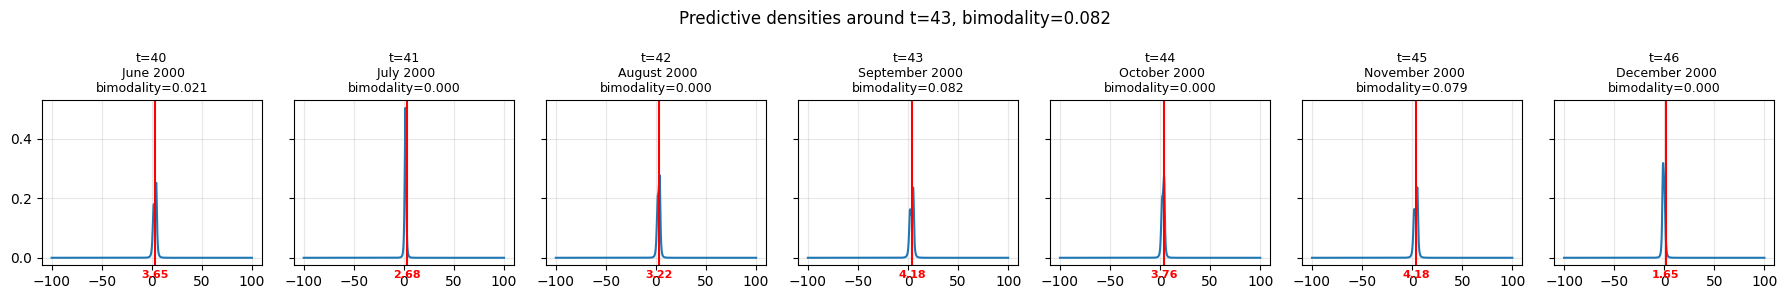

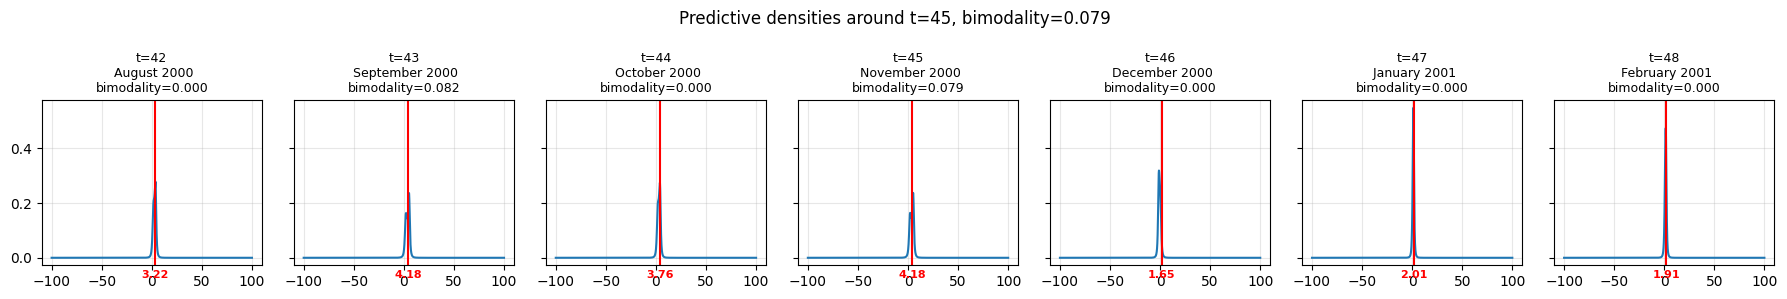

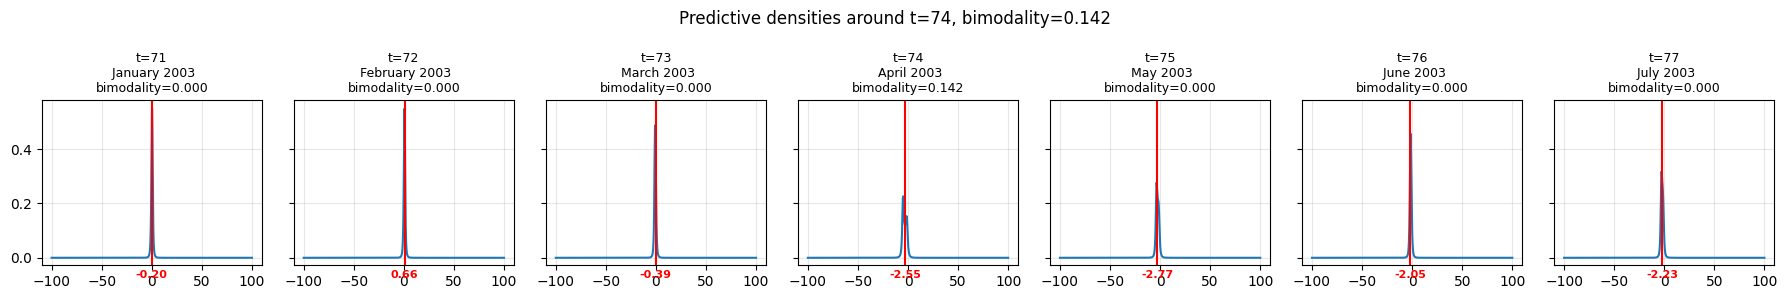

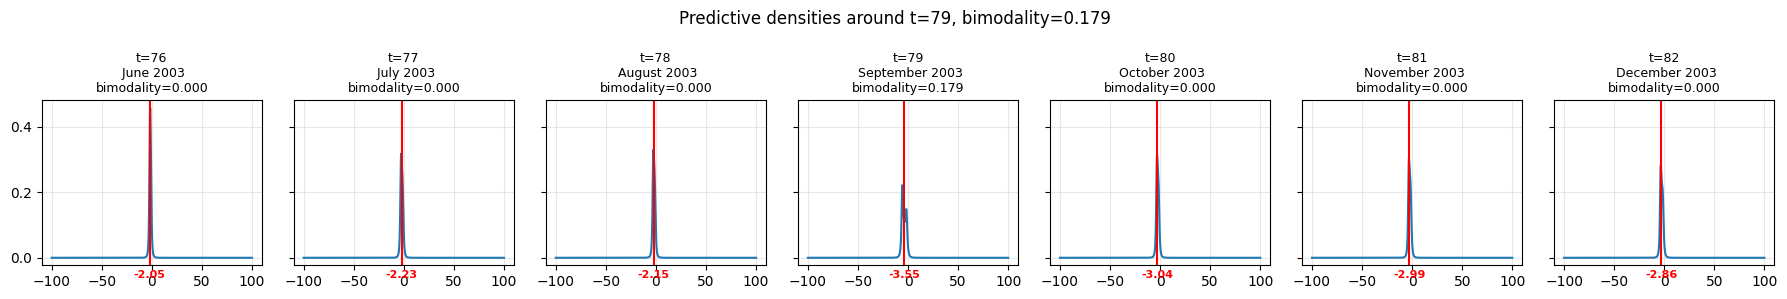

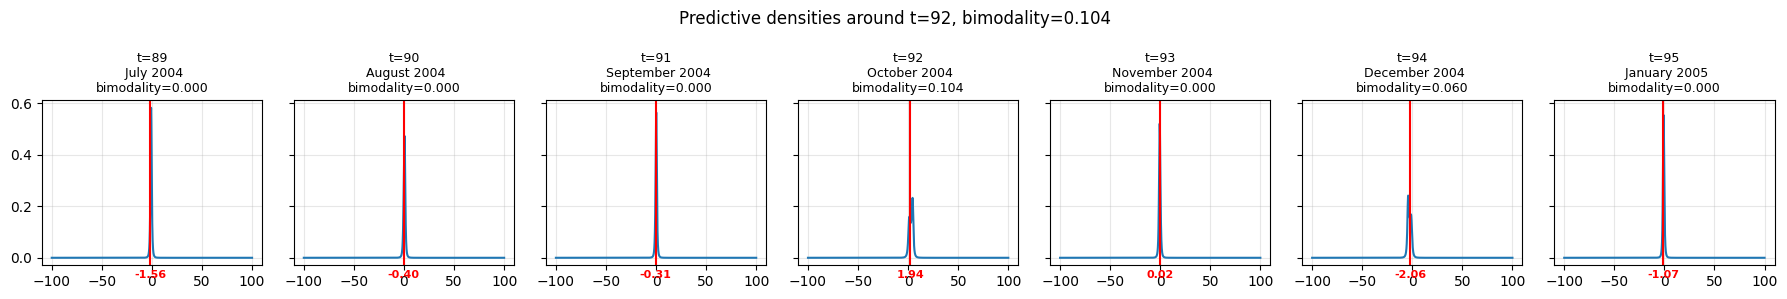

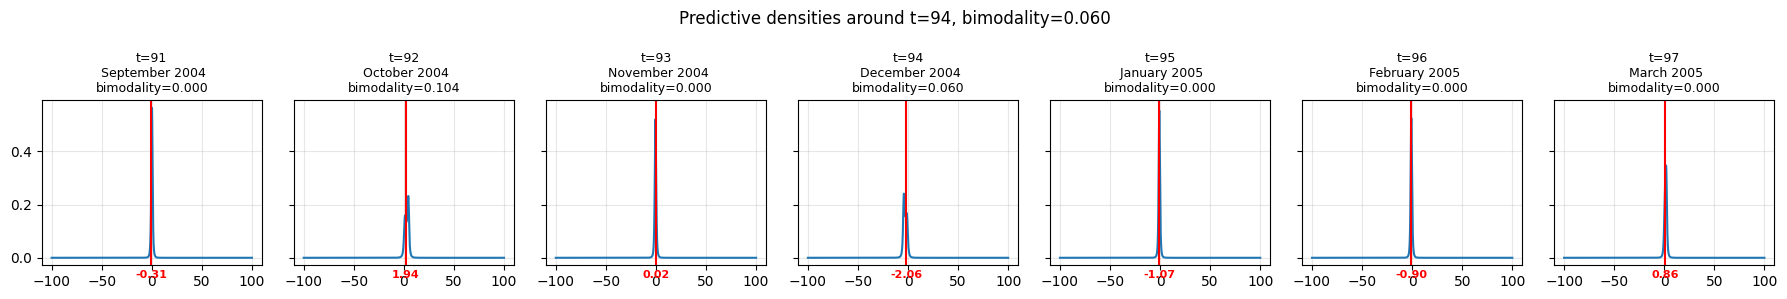

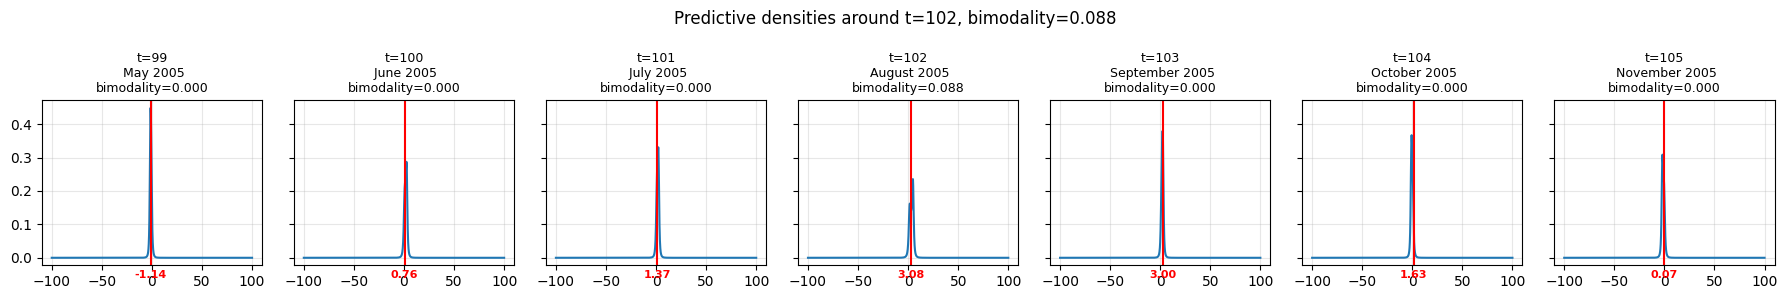

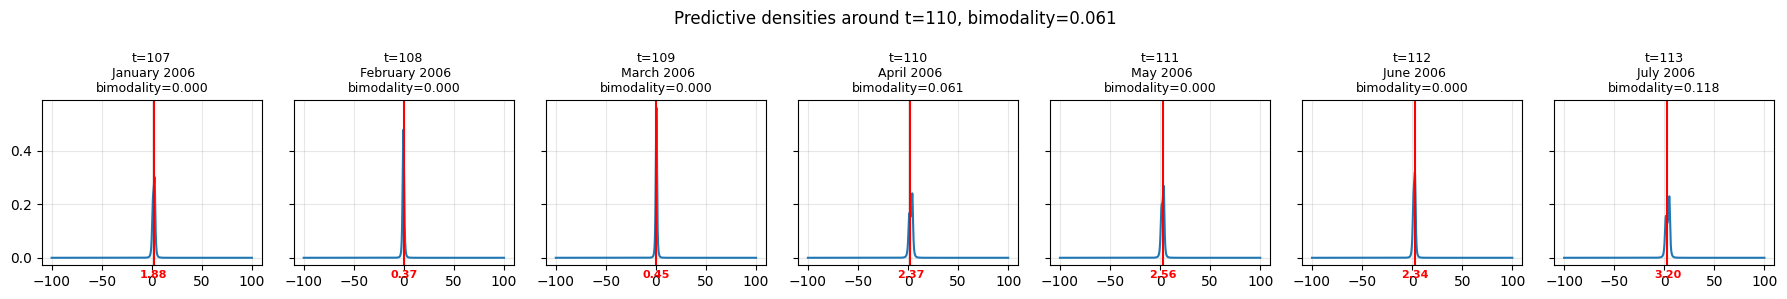

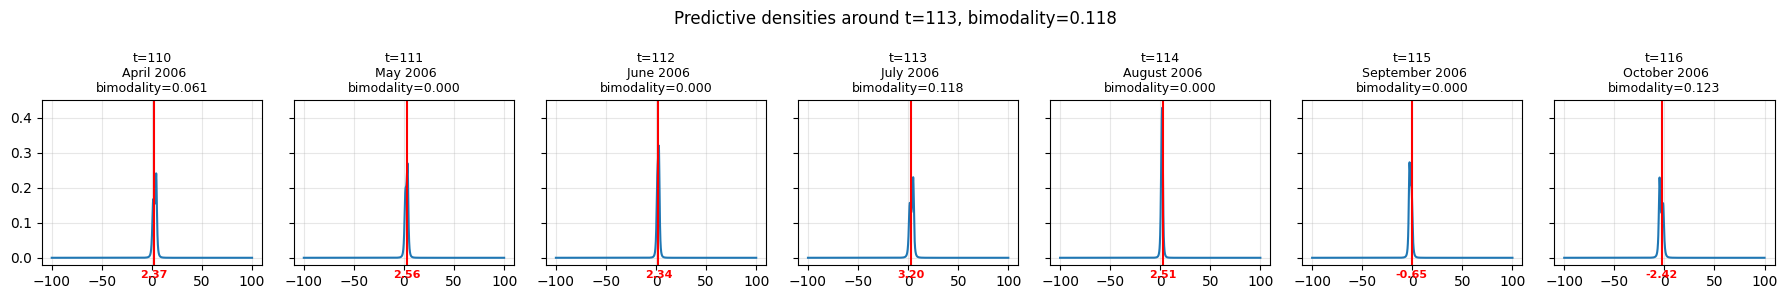

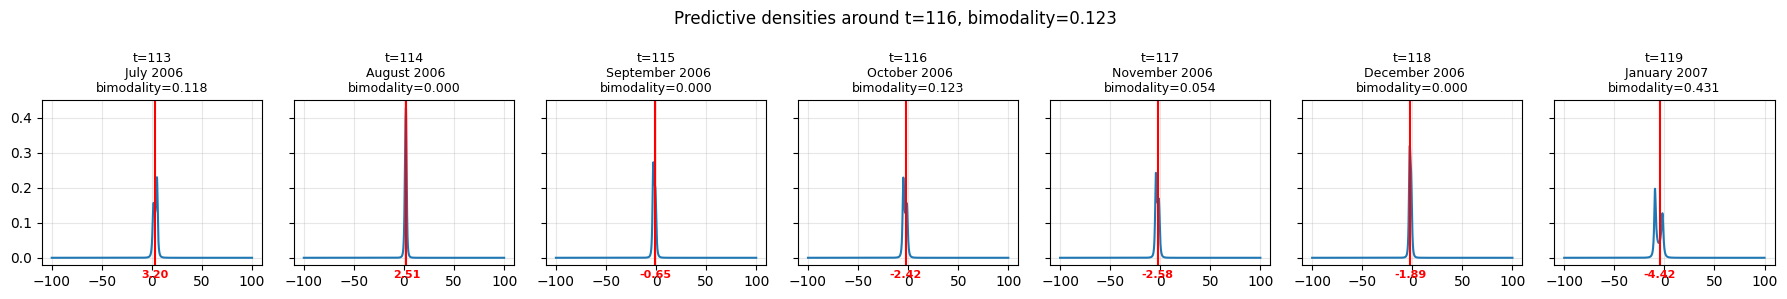

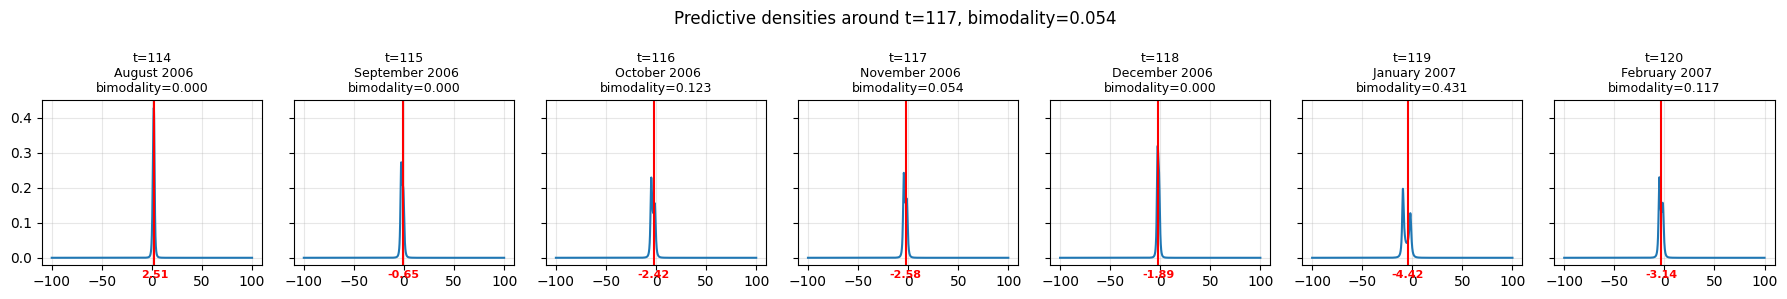

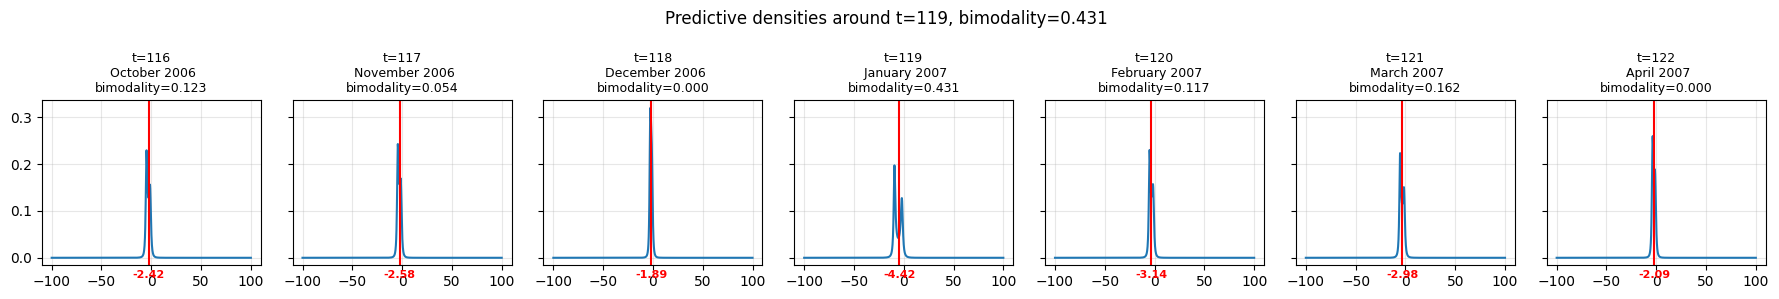

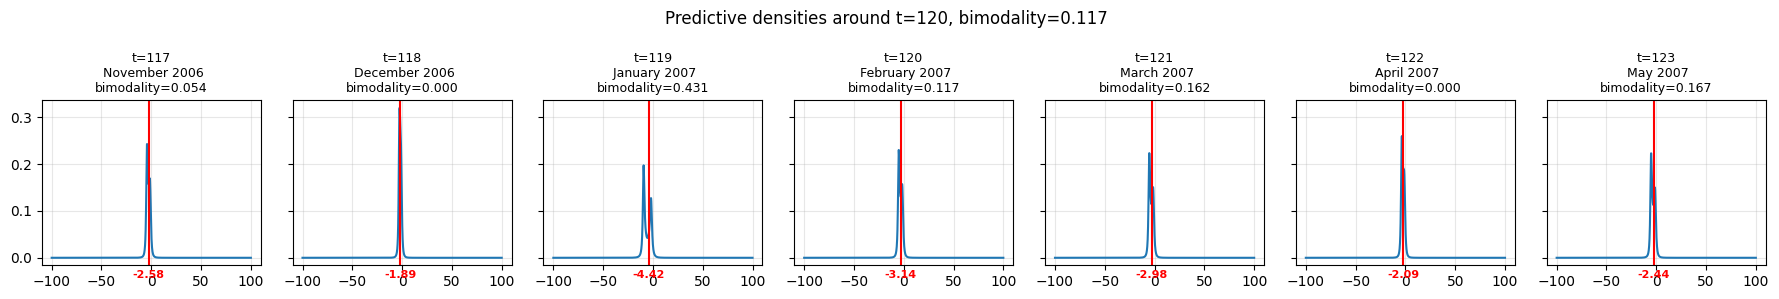

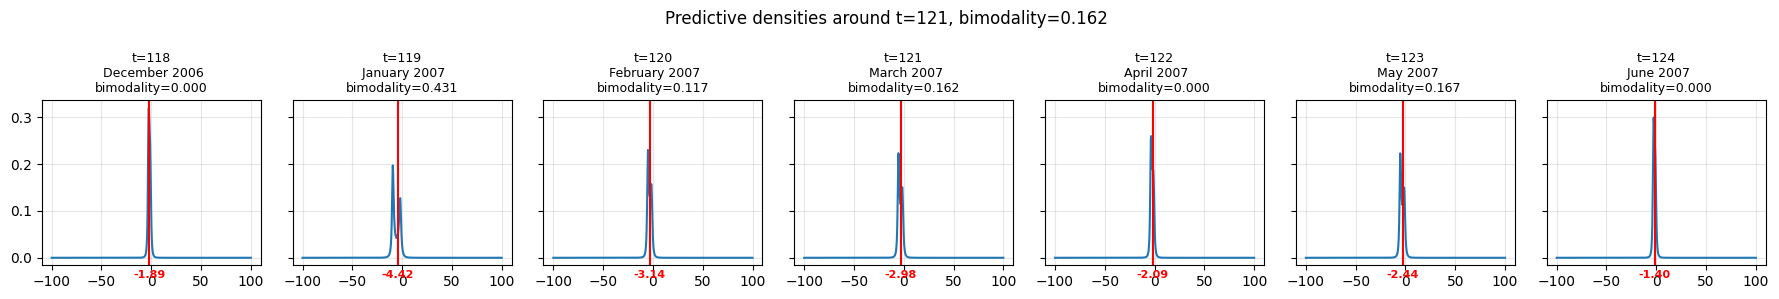

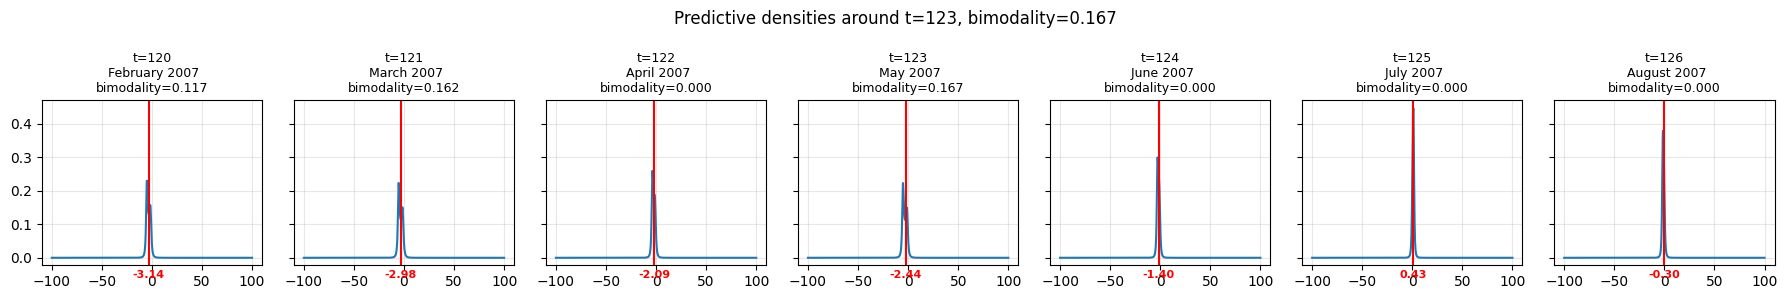

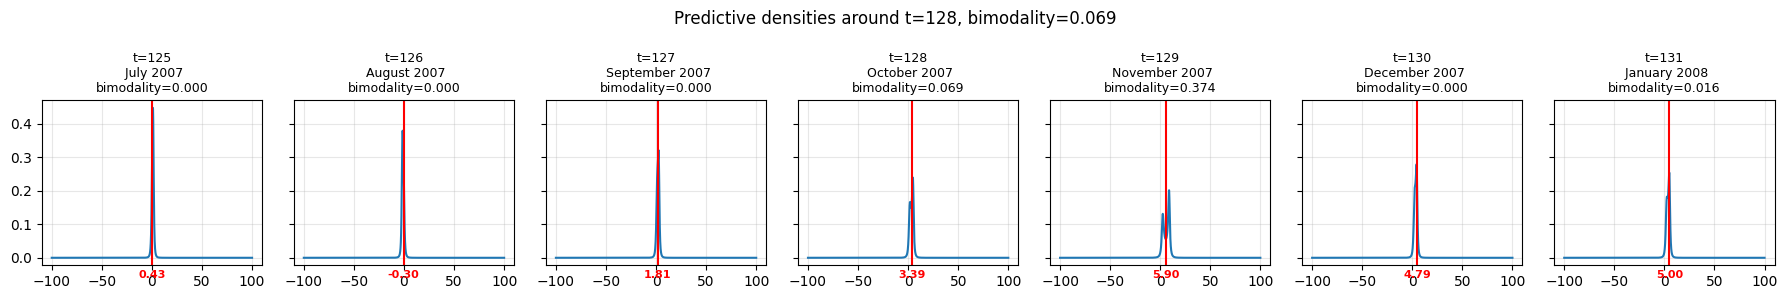

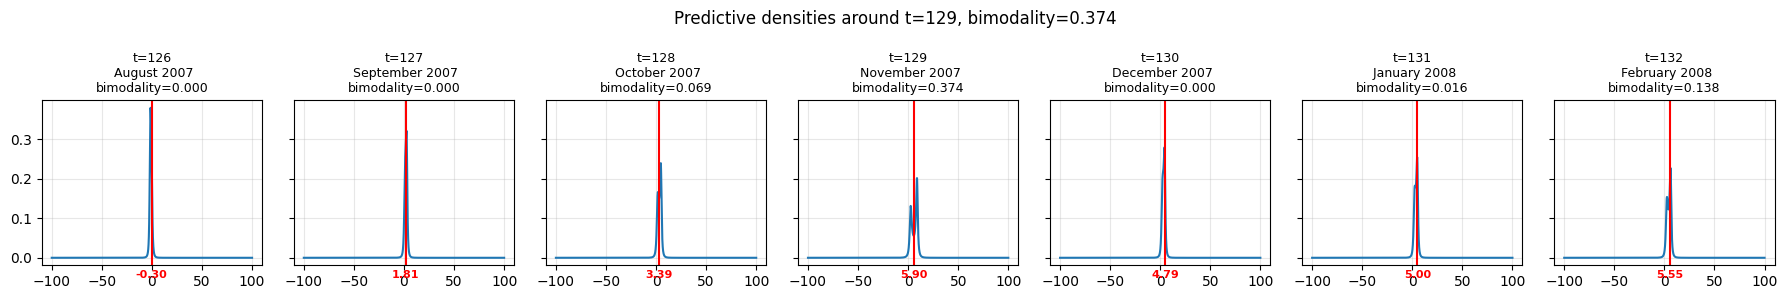

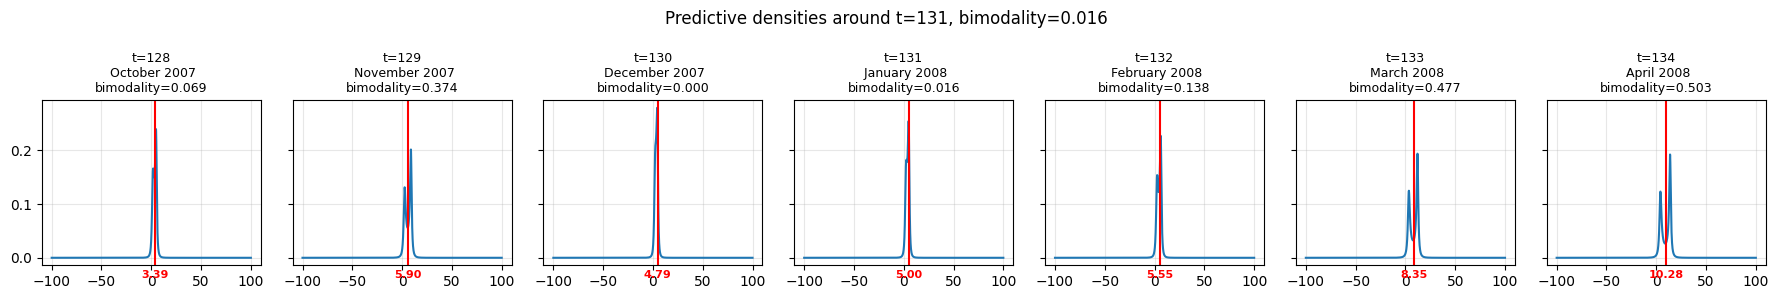

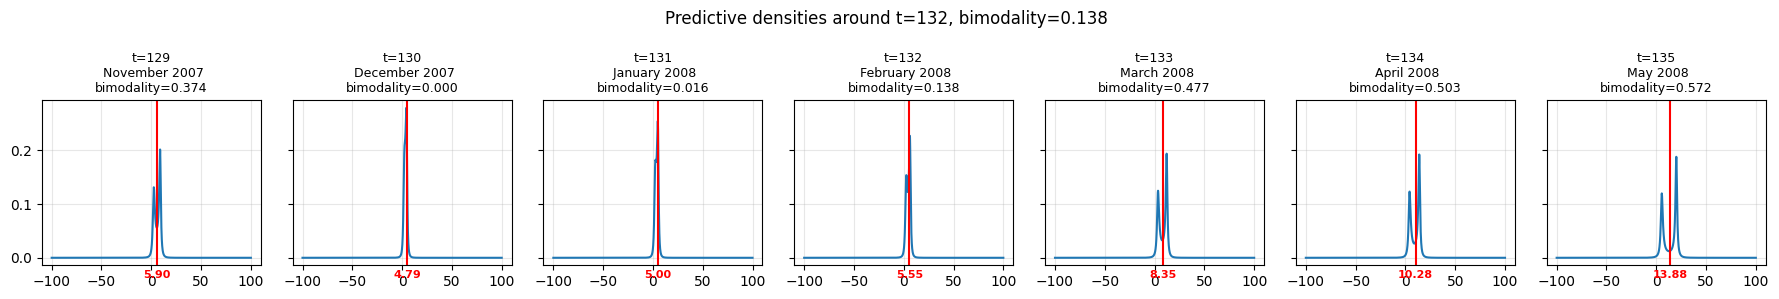

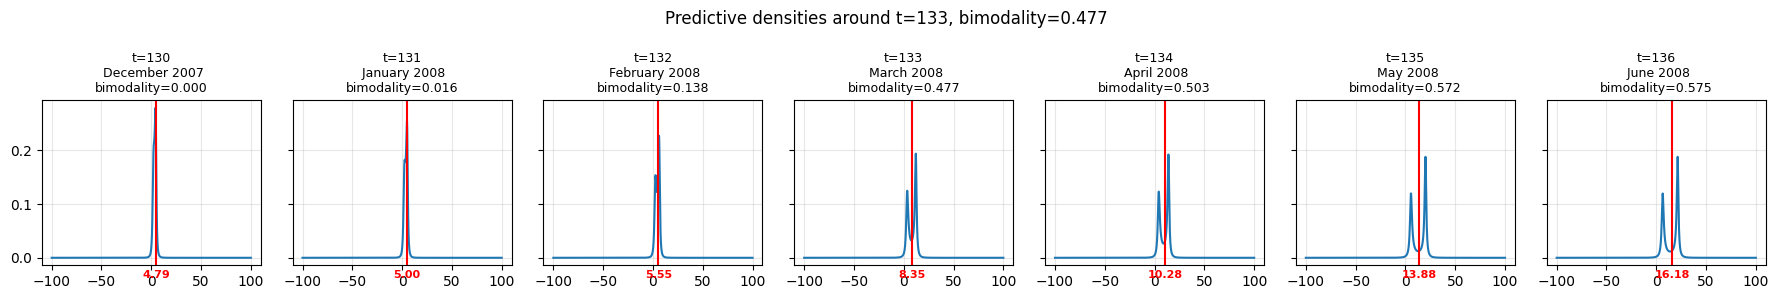

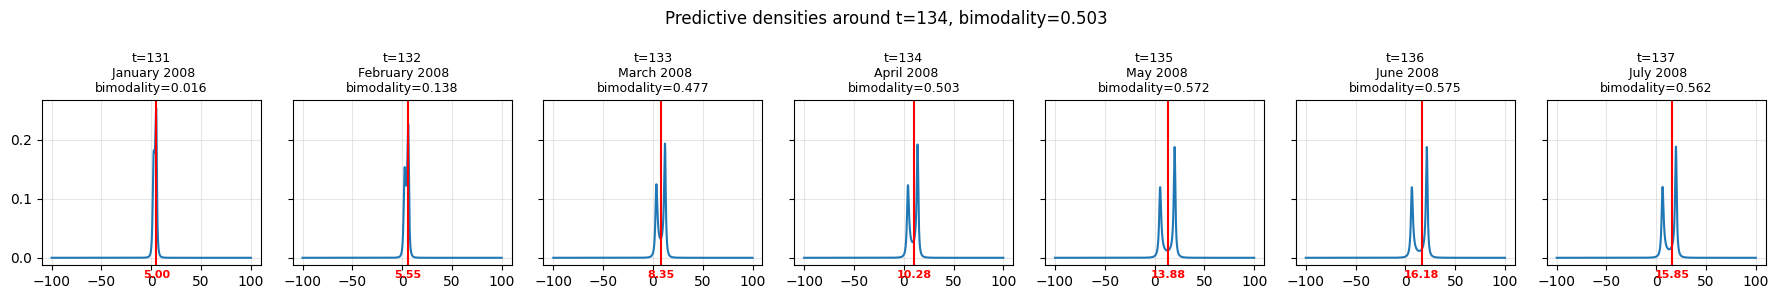

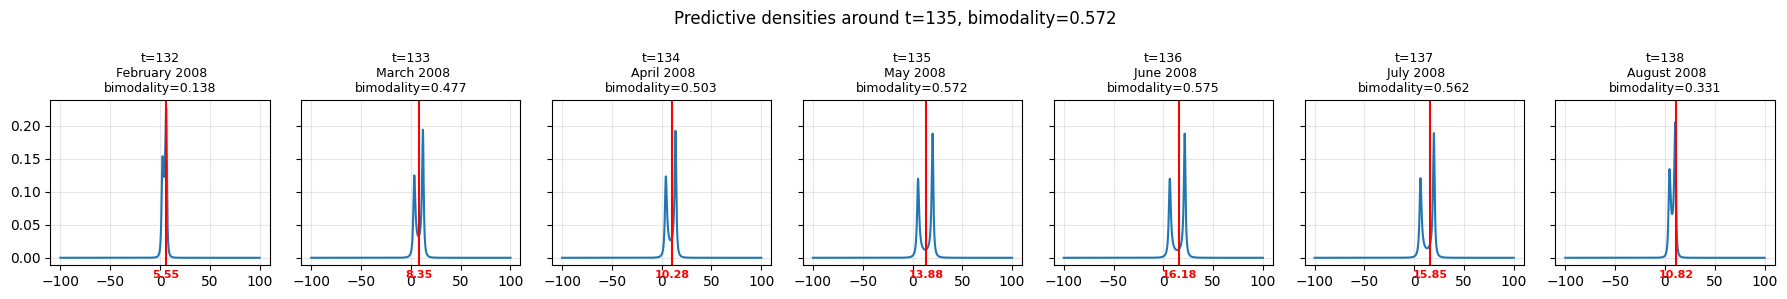

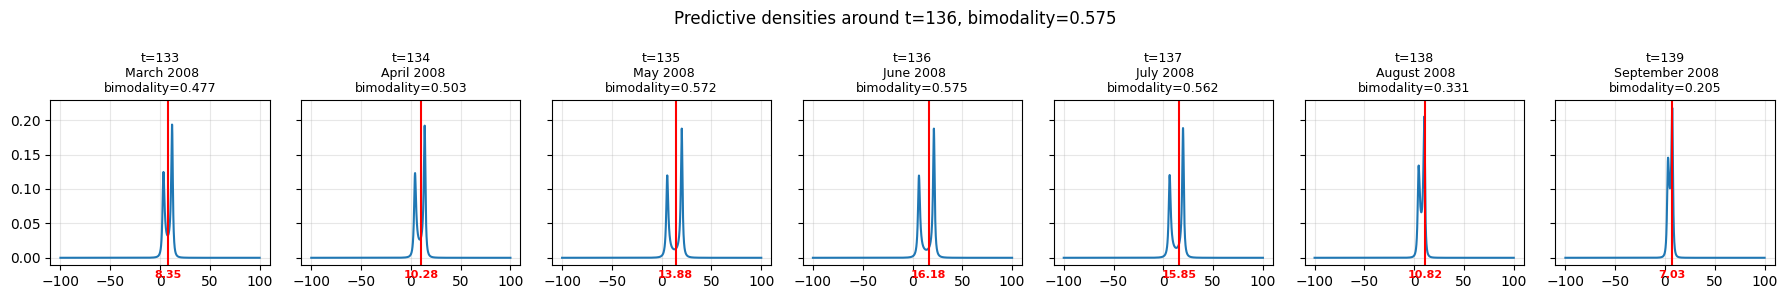

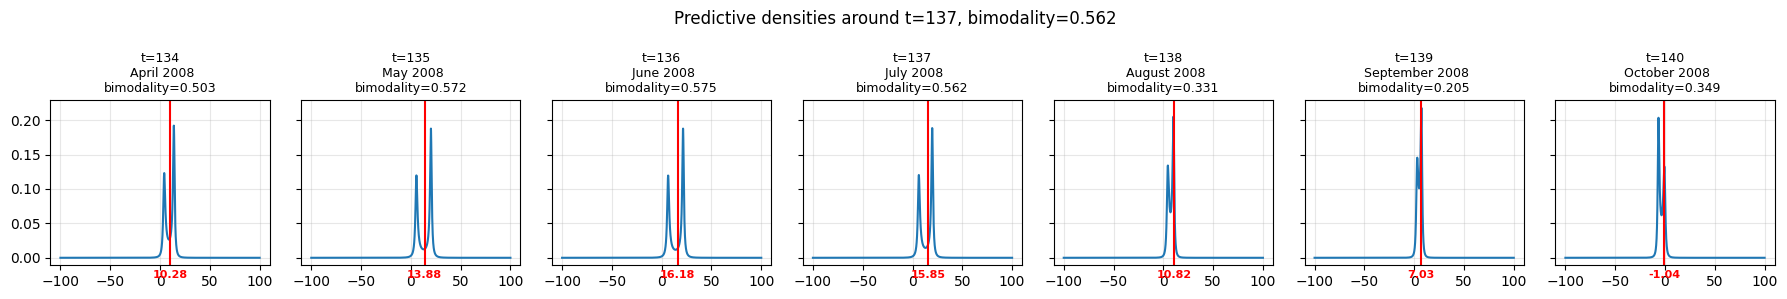

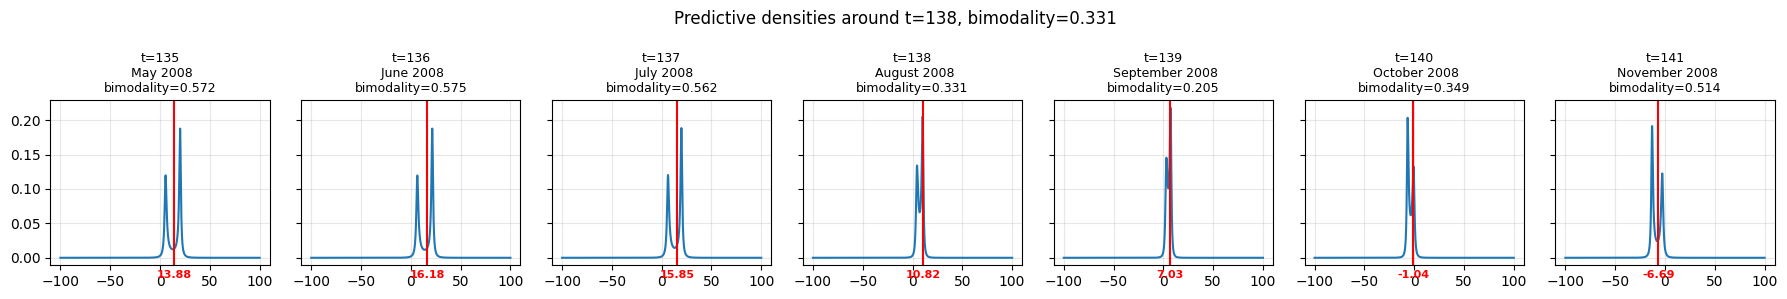

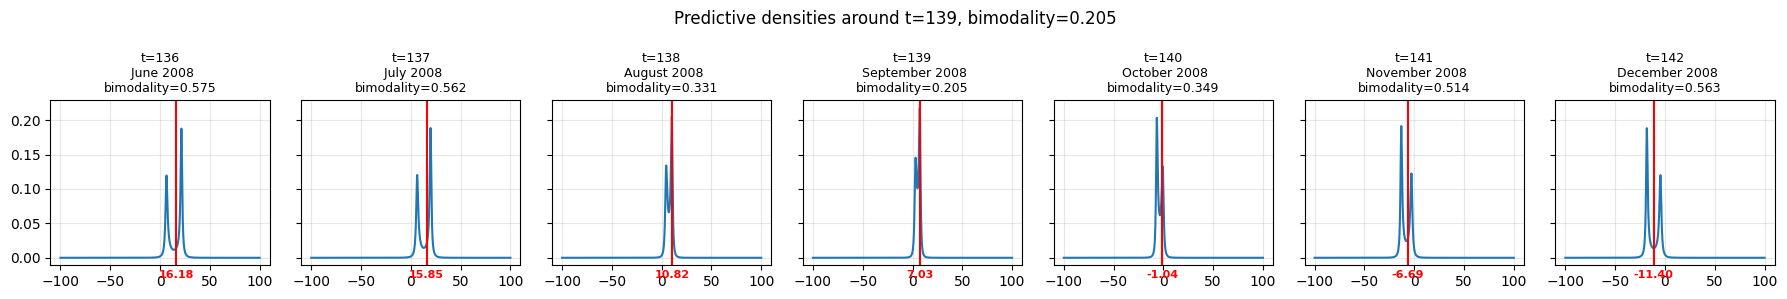

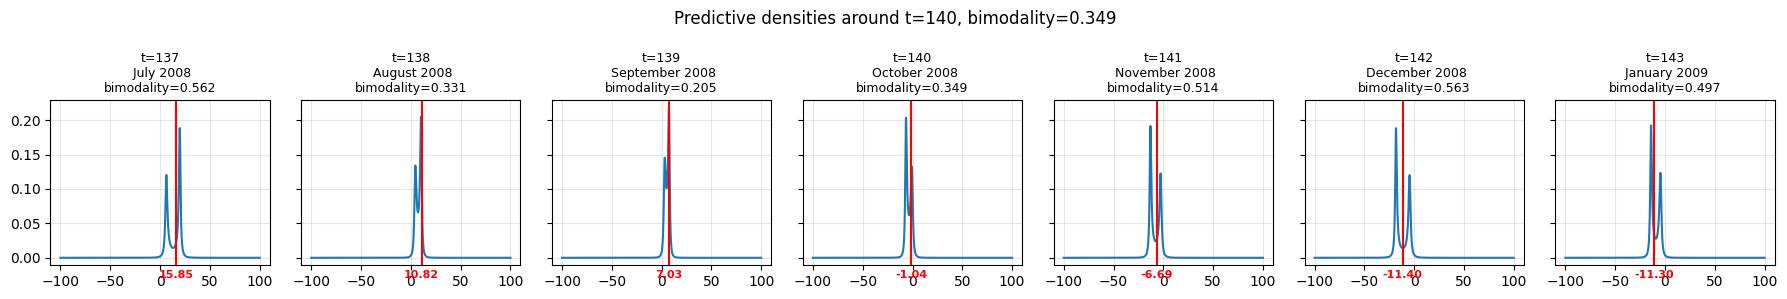

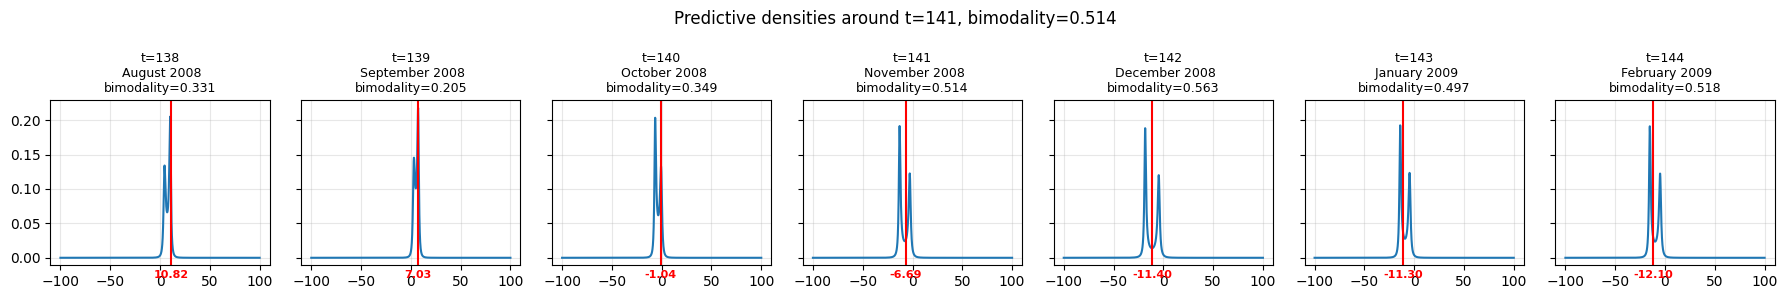

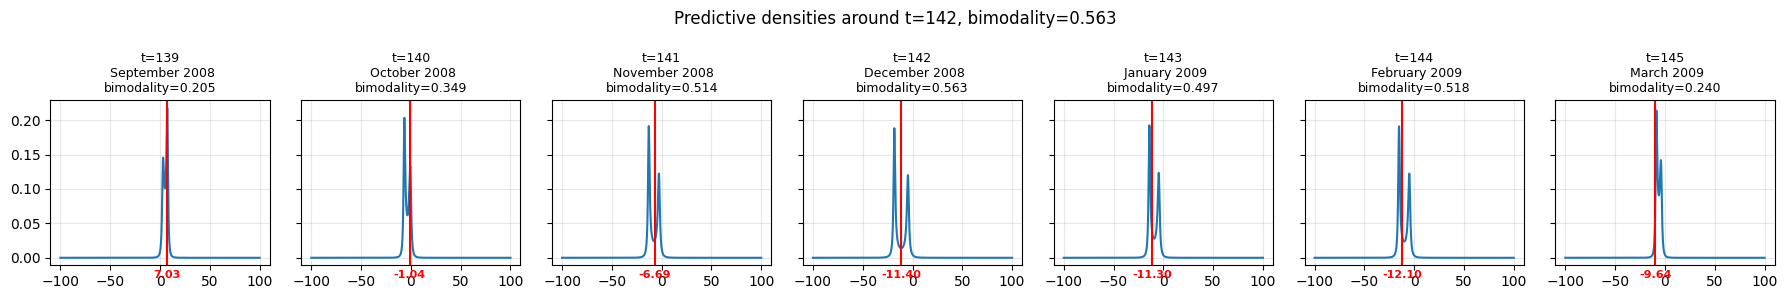

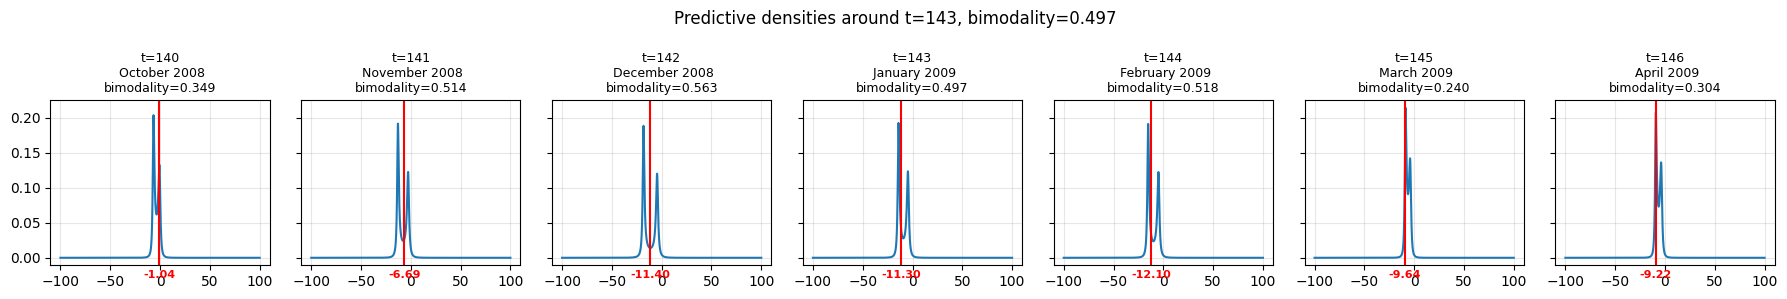

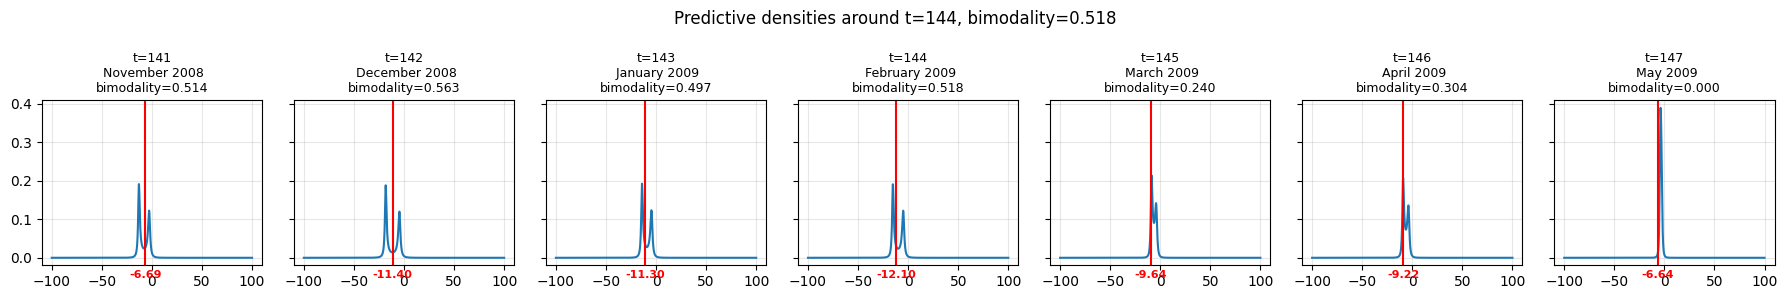

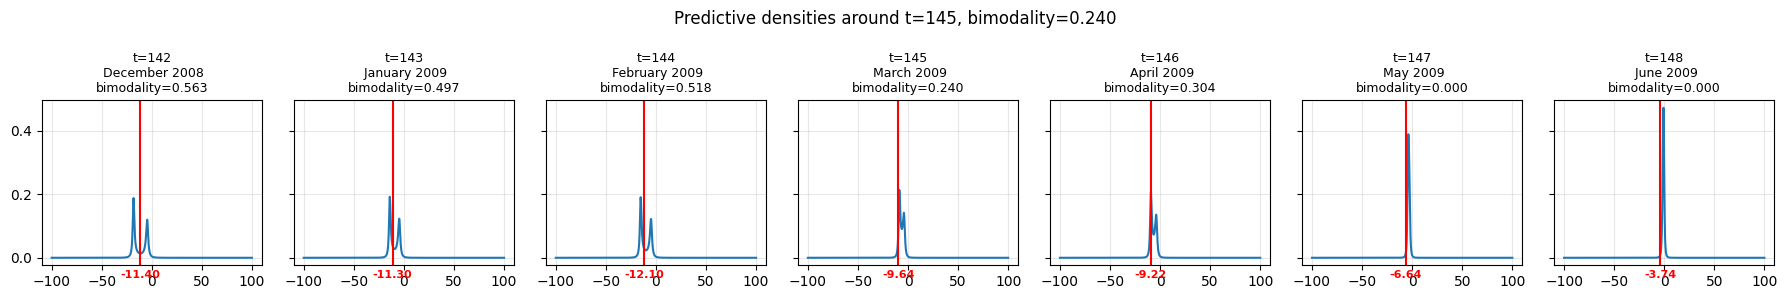

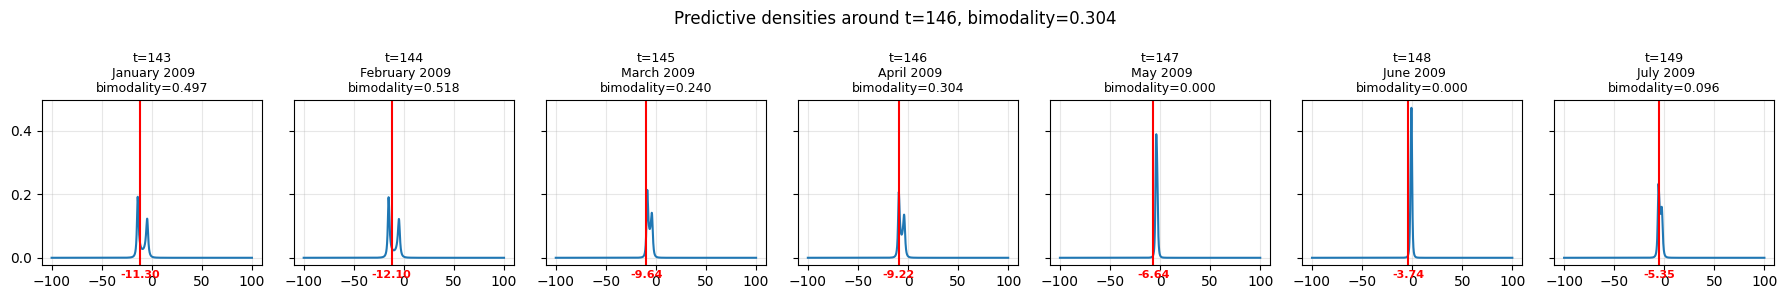

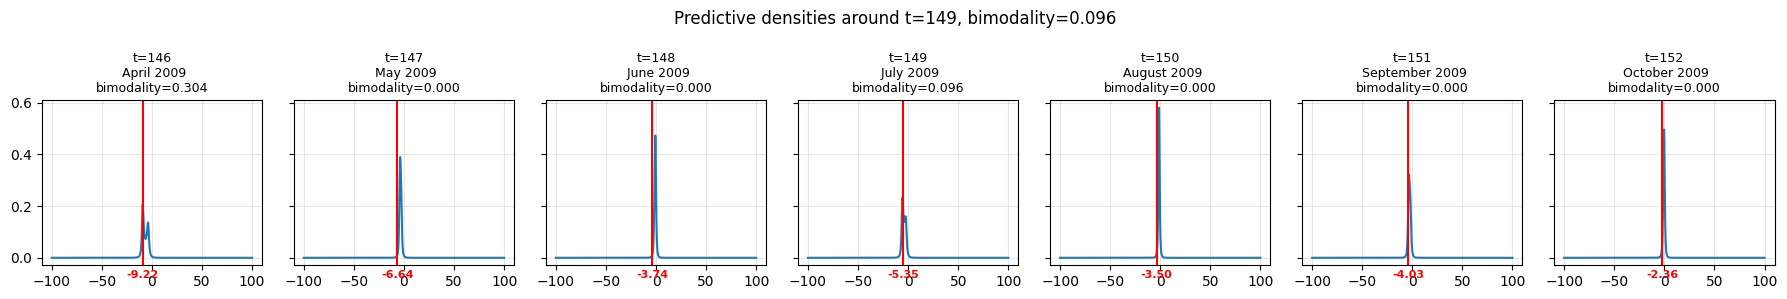

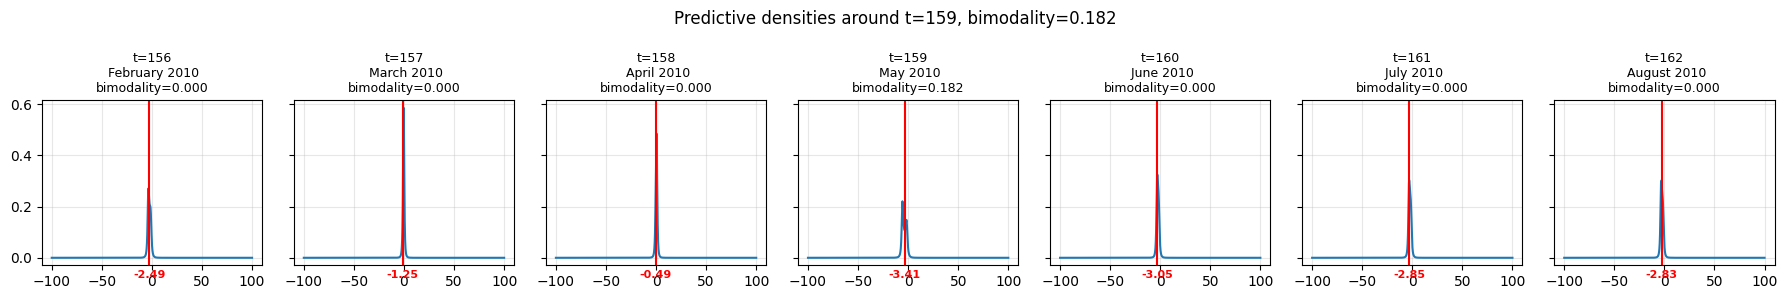

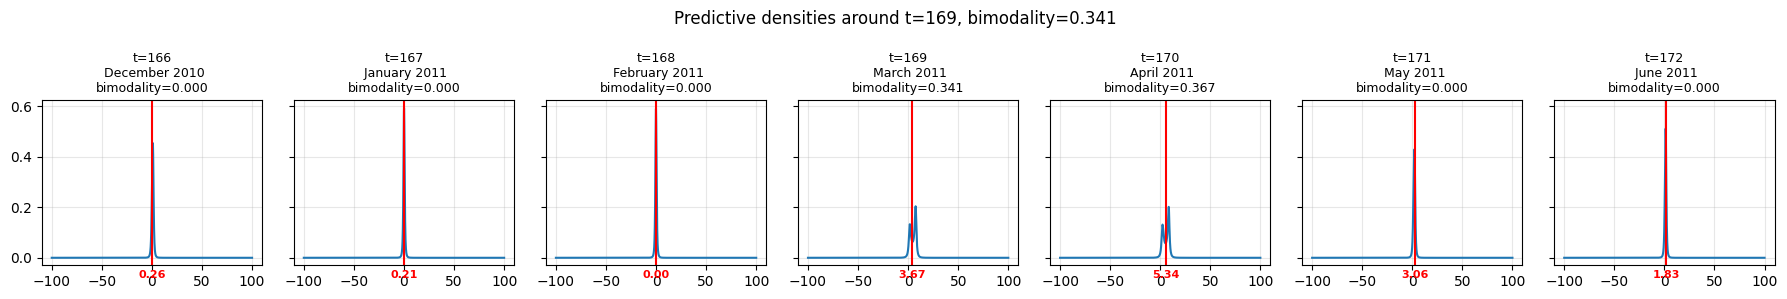

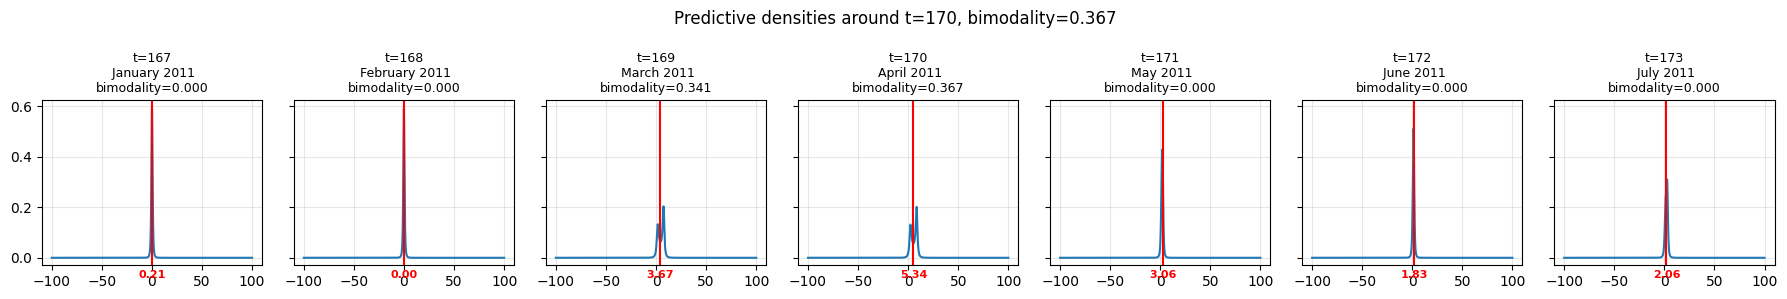

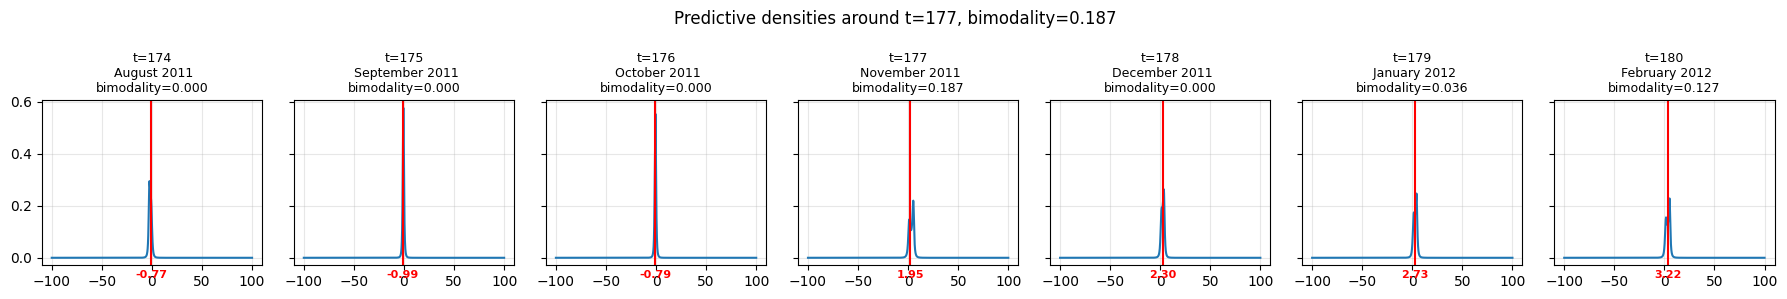

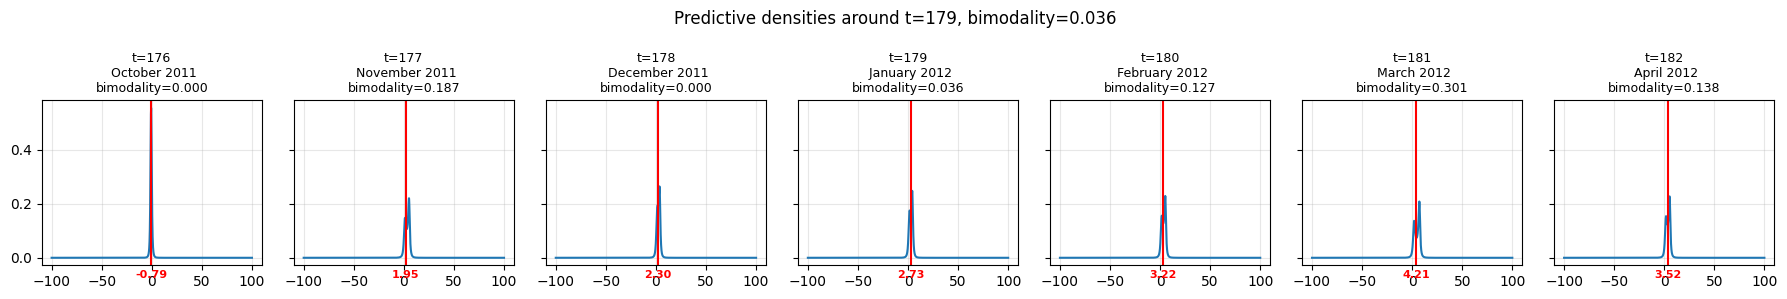

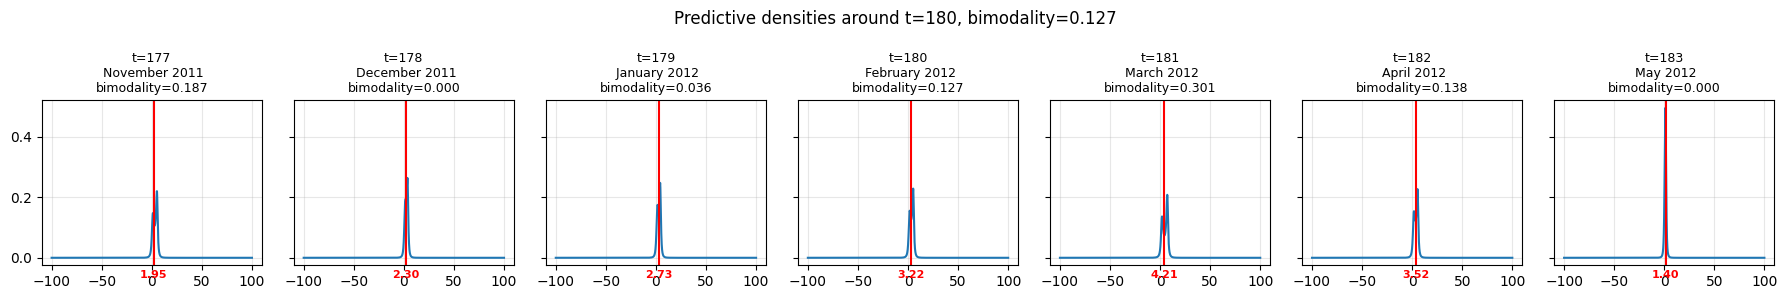

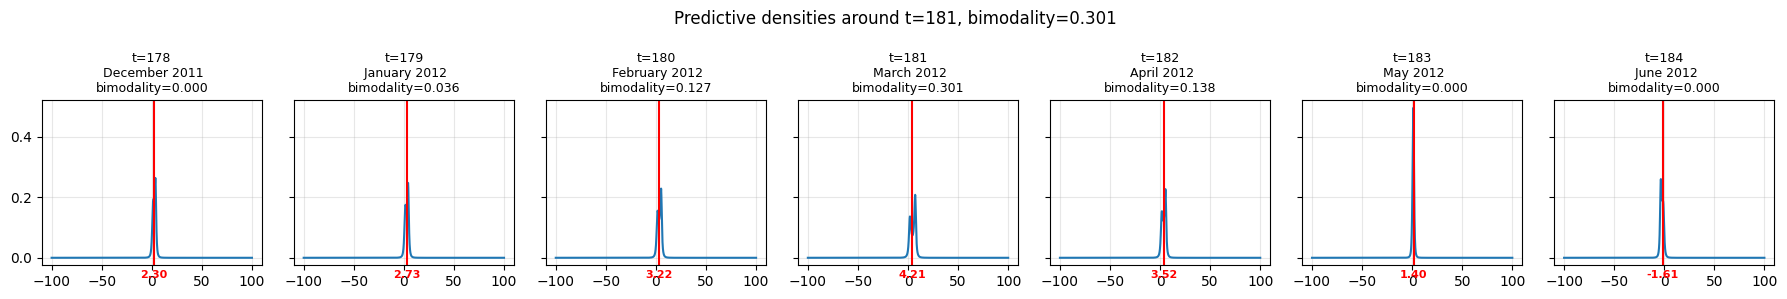

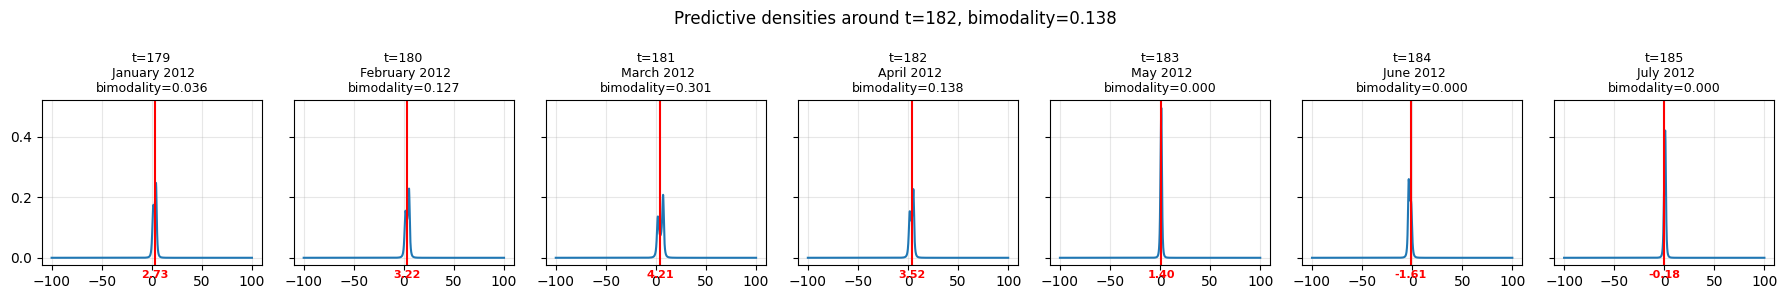

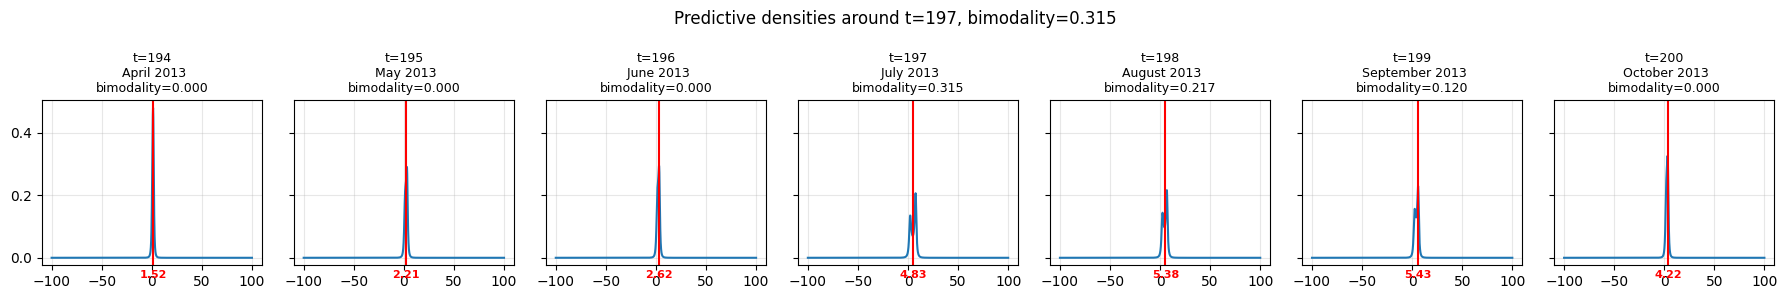

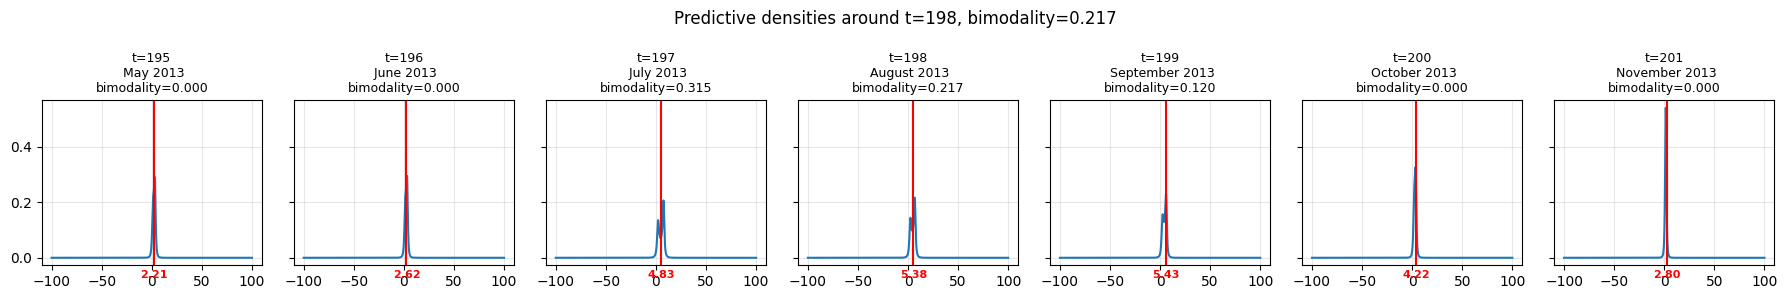

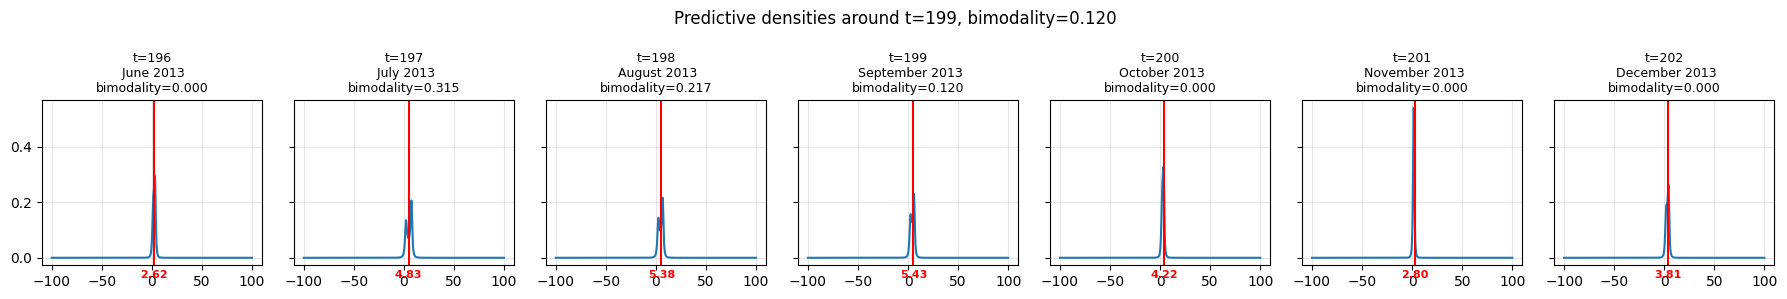

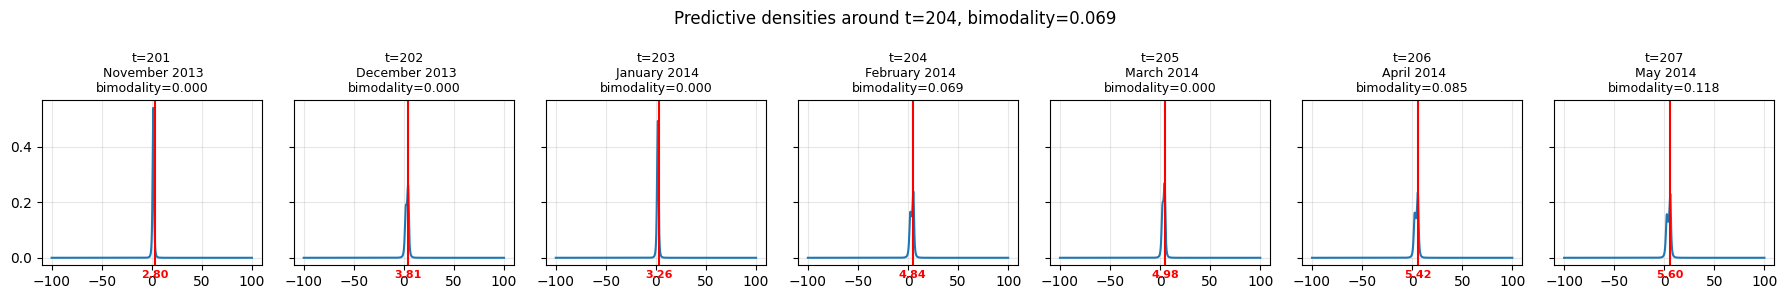

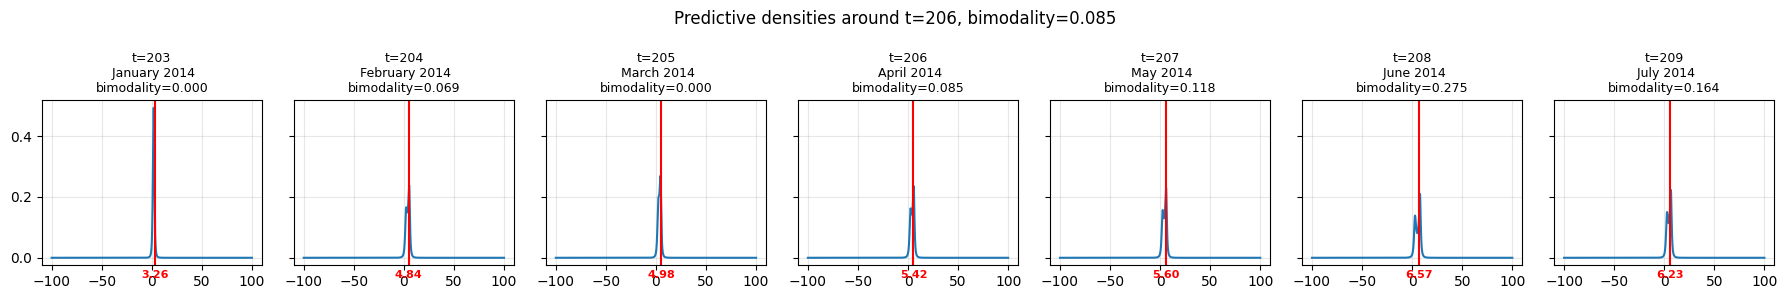

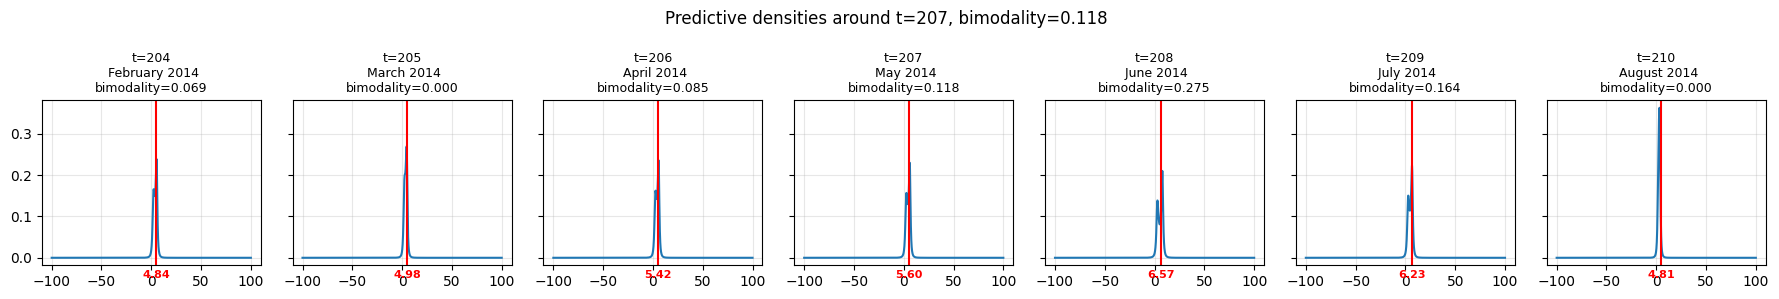

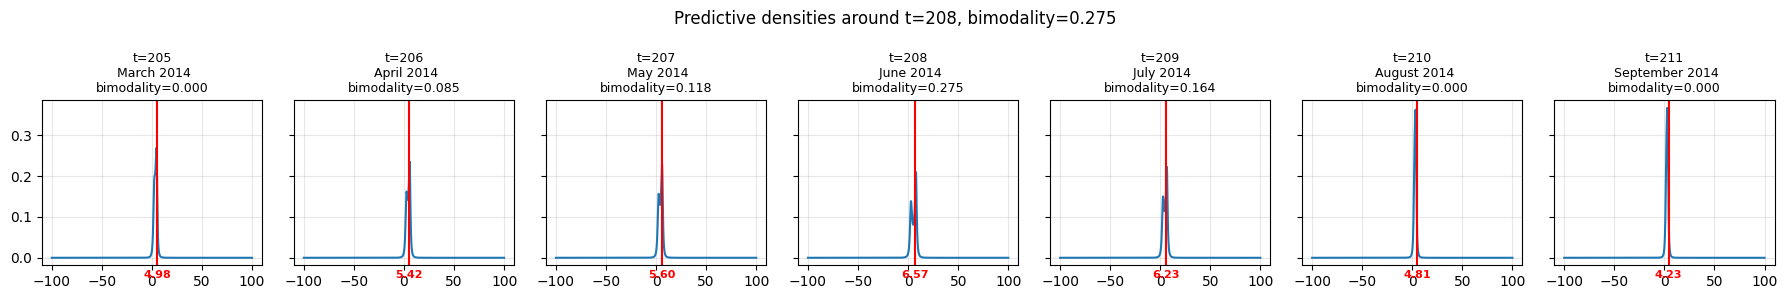

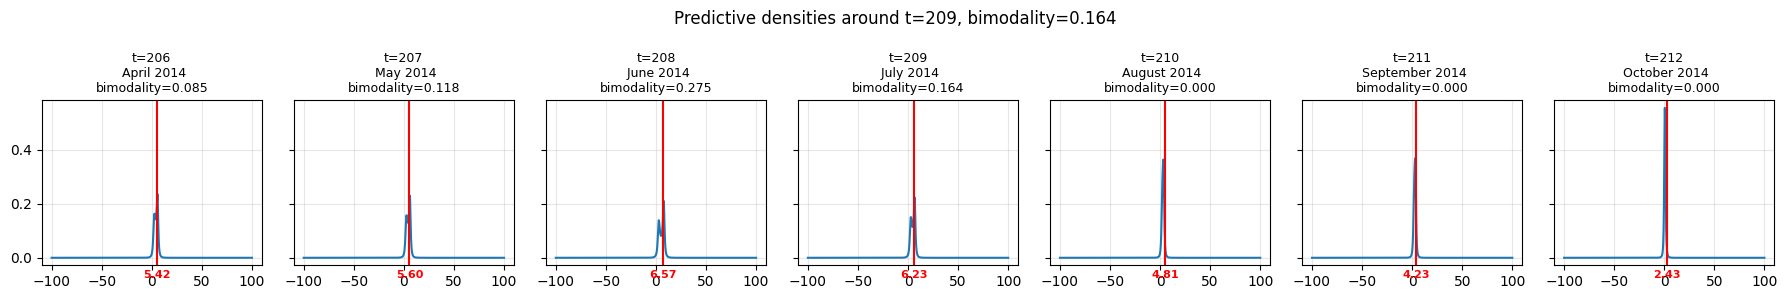

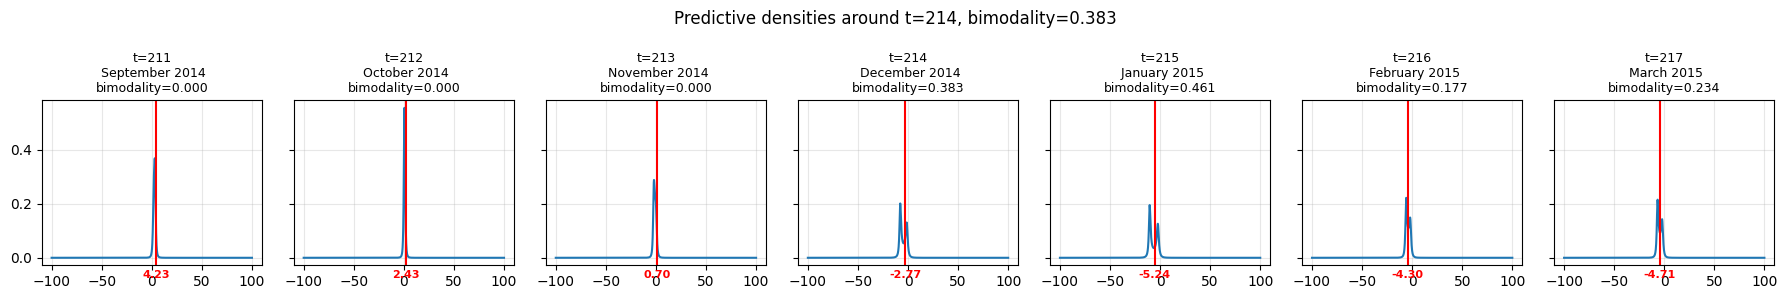

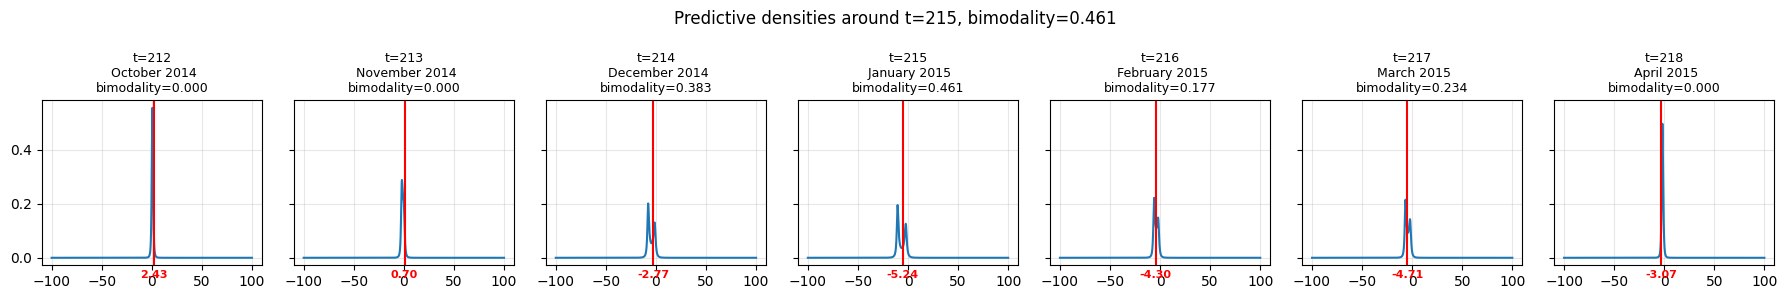

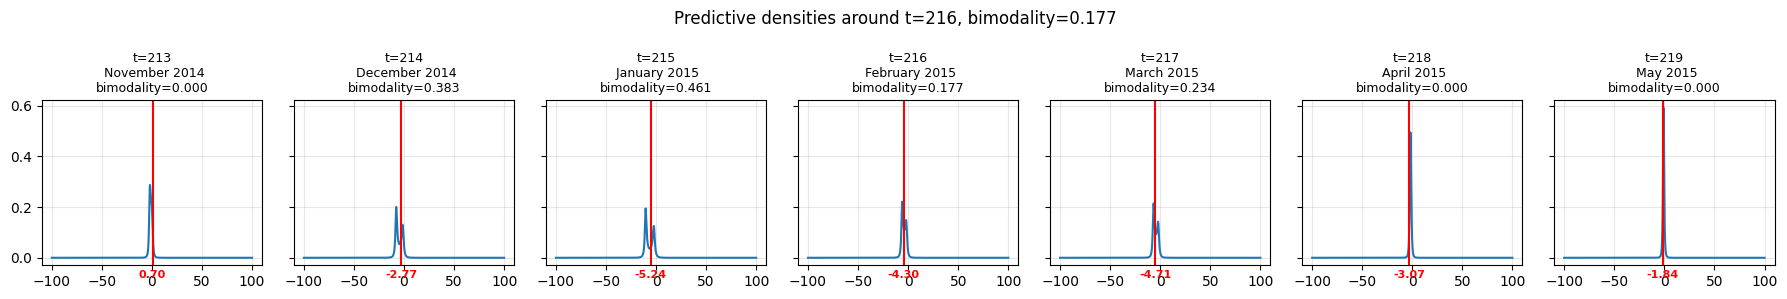

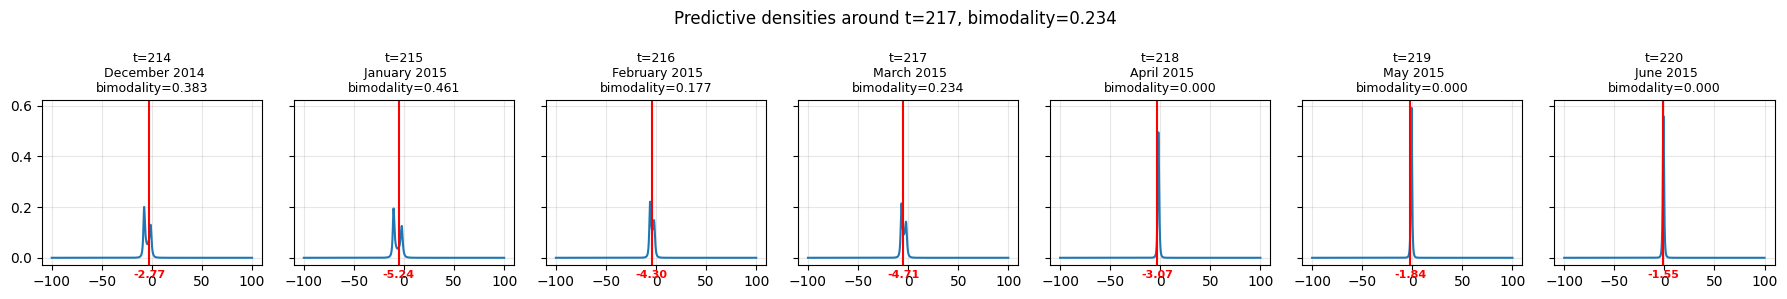

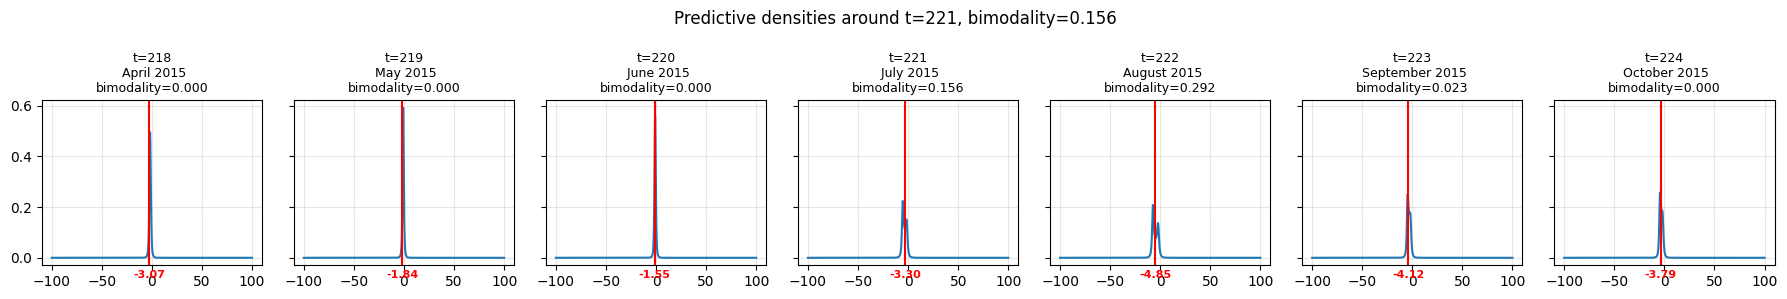

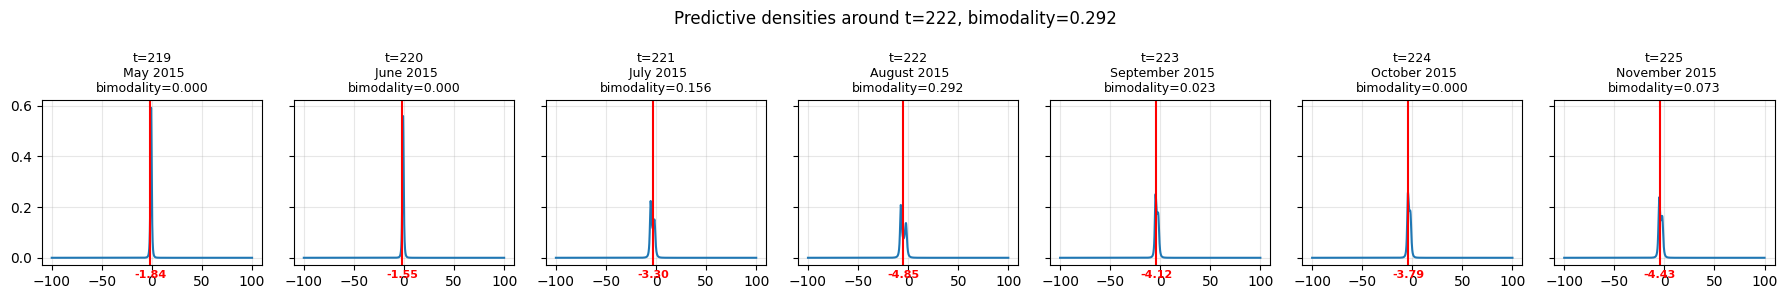

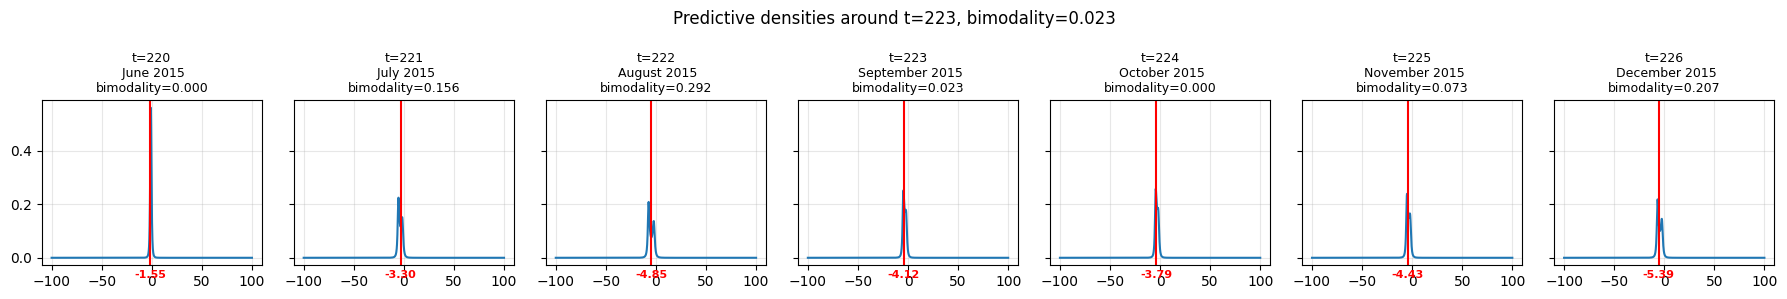

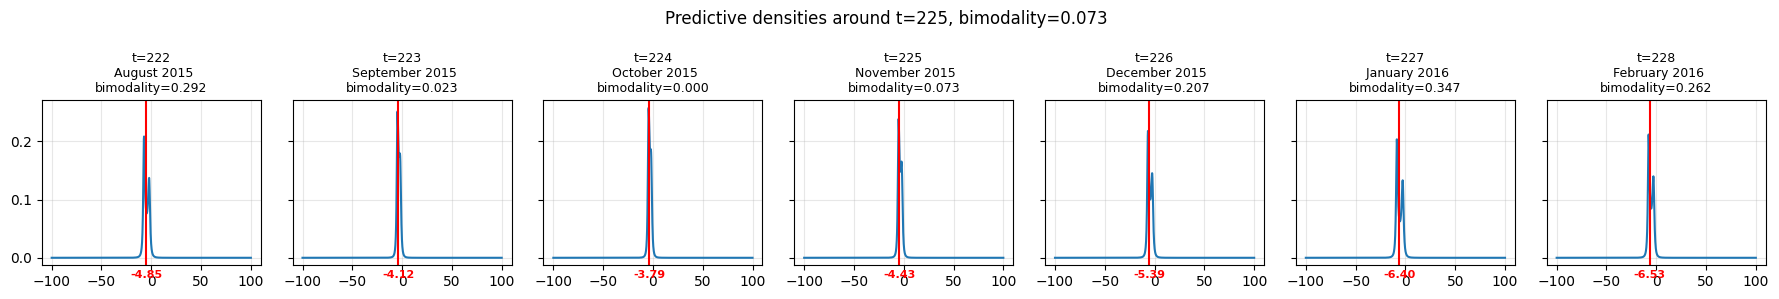

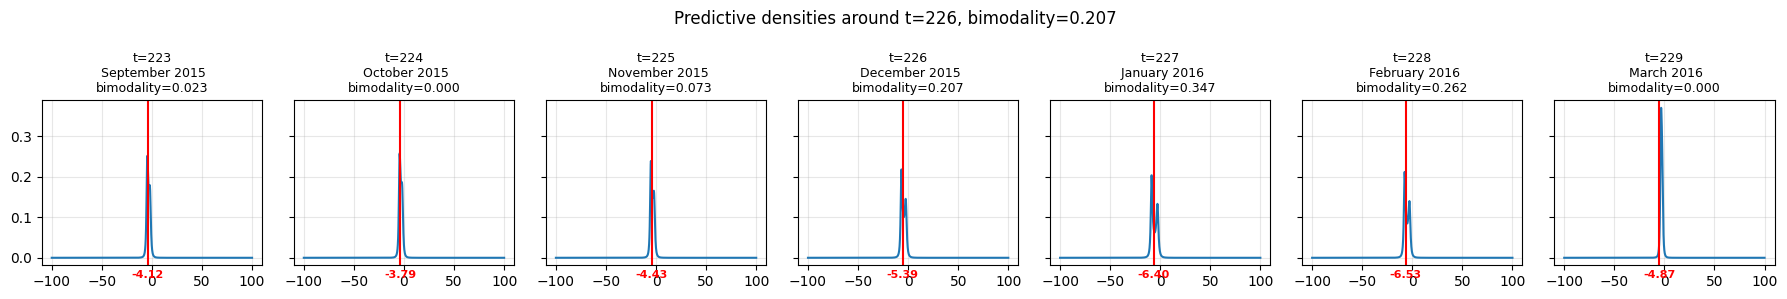

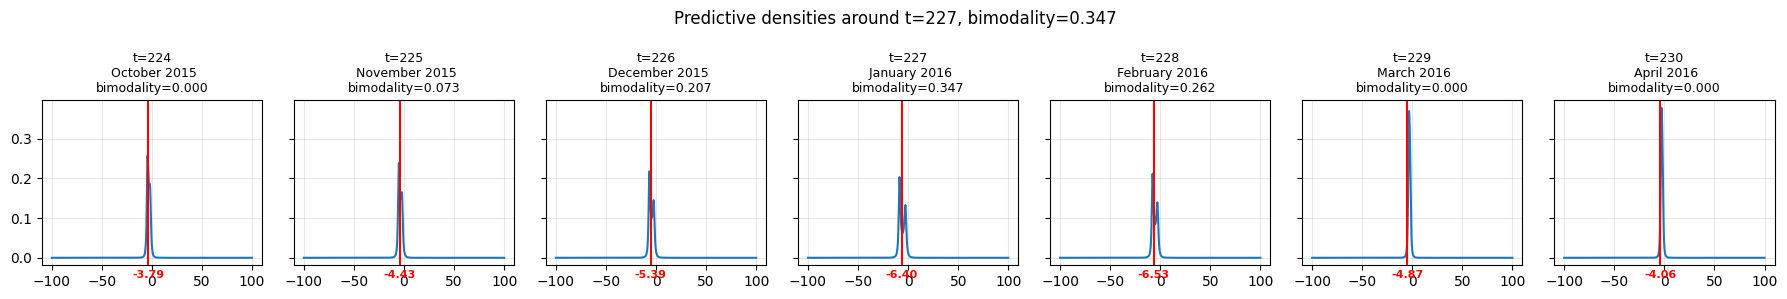

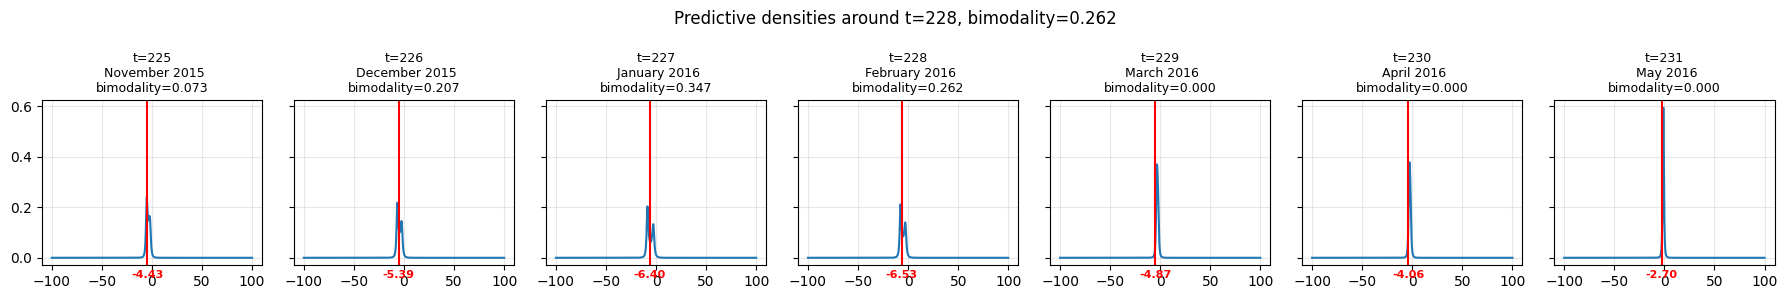

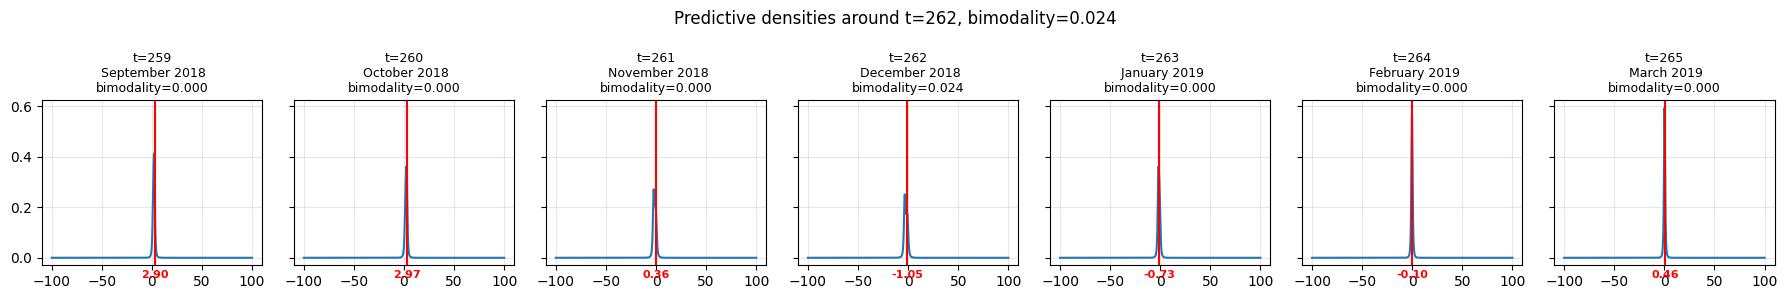

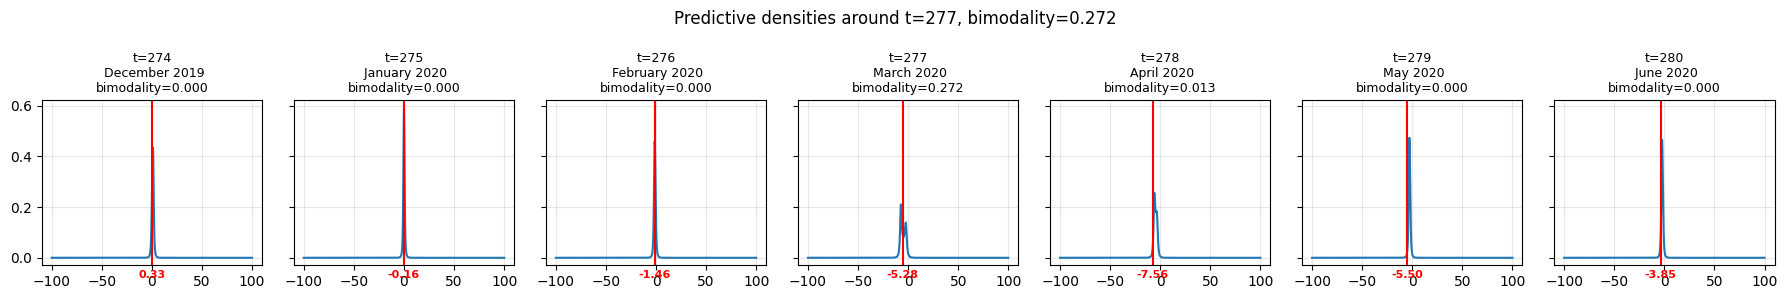

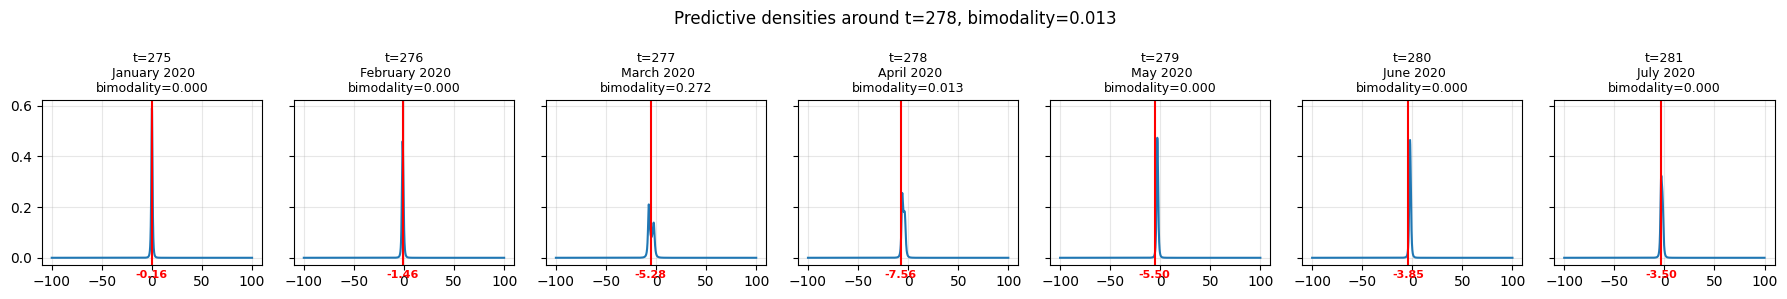

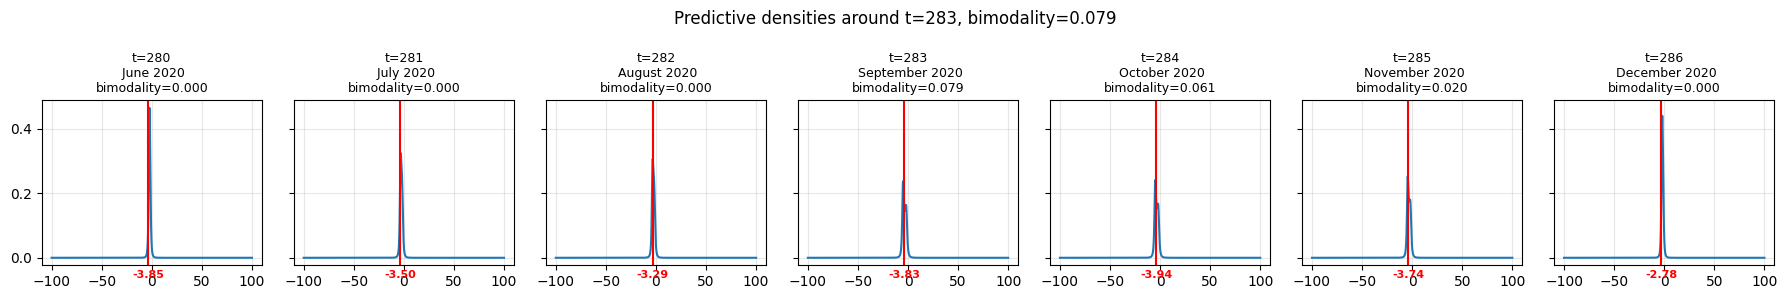

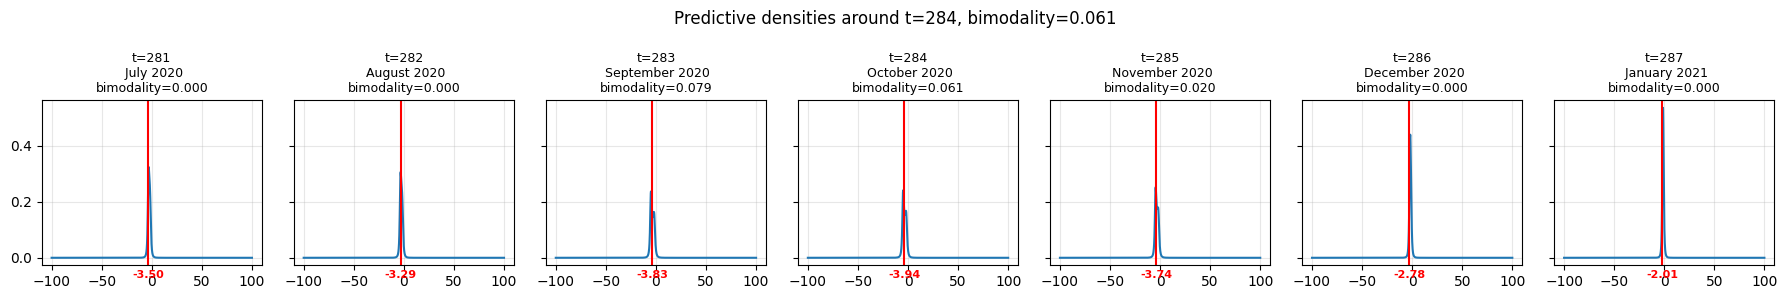

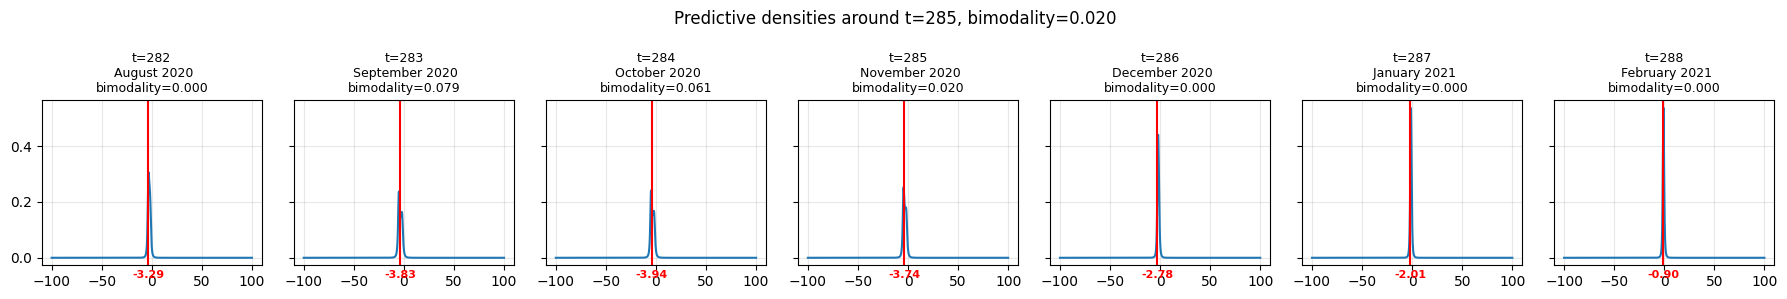

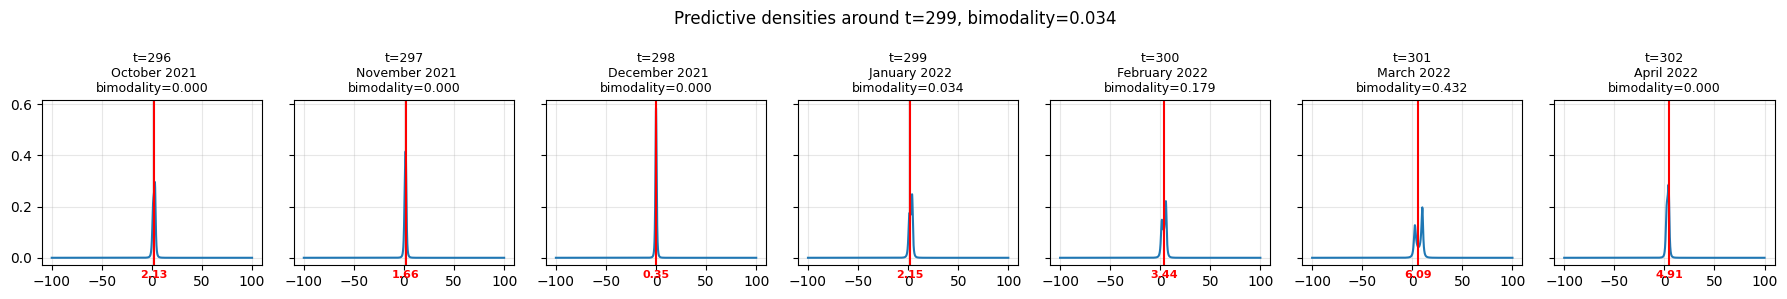

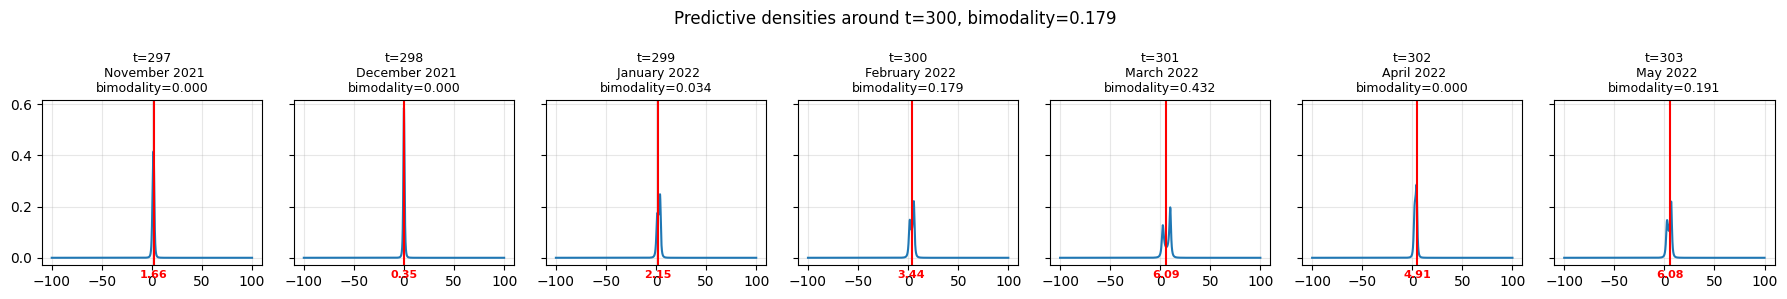

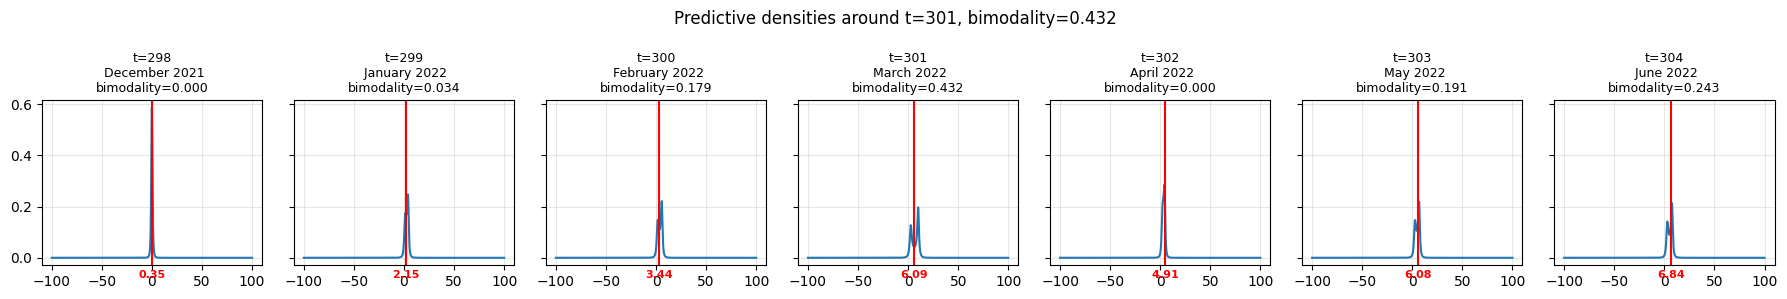

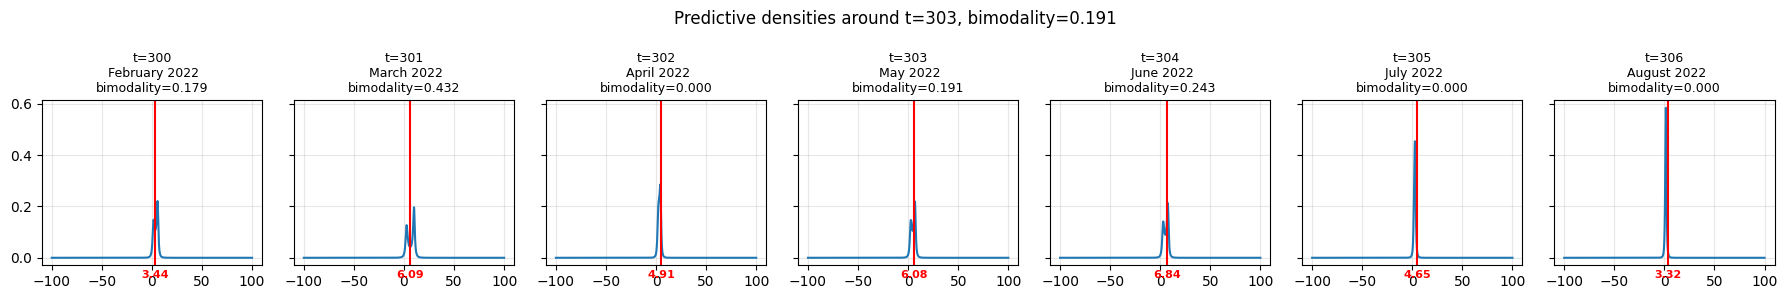

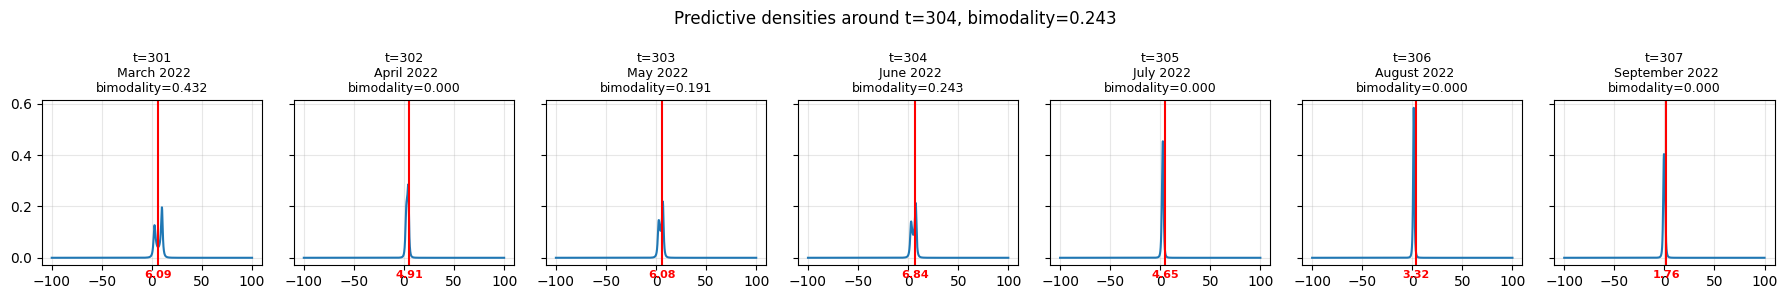

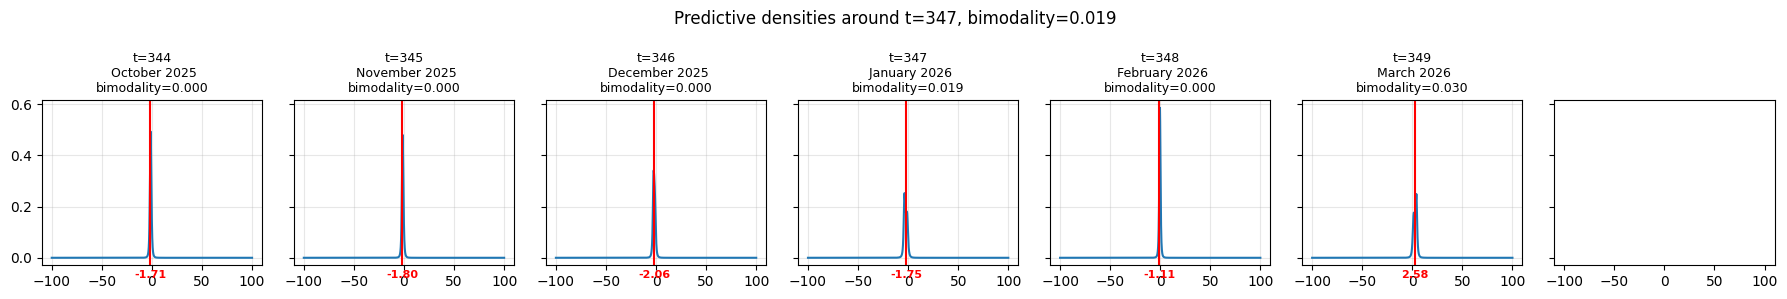

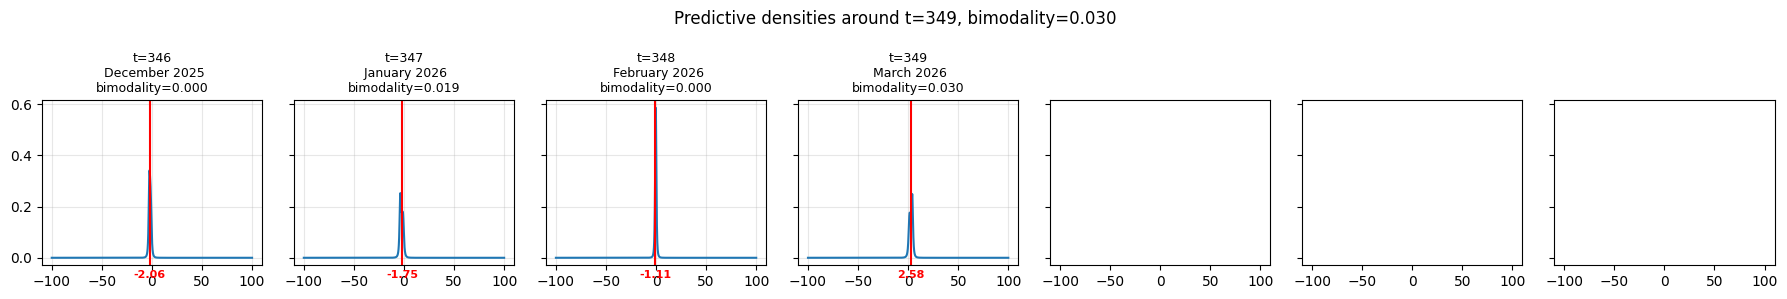

In [33]:
bimodal_times = np.asarray(times)[np.asarray(bimodality_series) != 0]

print("Bimodal times:")
print(bimodal_times)


grid = np.linspace(-100, 100, 2000)

window = 3

for t0 in bimodal_times:

    # Find where this time is located in the times array
    idx = np.where(times == t0)[0][0]

    idx_start = max(0, idx - window)
    idx_end   = min(len(times) - 1, idx + window)

    fig, axes = plt.subplots(1, 7, figsize=(18, 3), sharex=True, sharey=True)
    axes = np.ravel(axes)

    for ax, j in zip(axes, range(idx_start, idx_end + 1)):
        plot_predictive_density_simple(
            ax=ax,
            predictive_density_fn=marx_cauchy_pred_density,
            grid=grid,
            y=y,
            X=X,
            t=times[j],
            params=params,
            title=f"t={times[j]}\n {df.index[times[j]].strftime('%B %Y')}\nbimodality={bimodality_series[j]:.3f}",
        )

    plt.suptitle(
        f"Predictive densities around t={t0}, "
        f"bimodality={bimodality_series[idx]:.3f}"
    )
    plt.tight_layout()
    plt.show()

### Bimodality/ Predictive Density changes for different X values

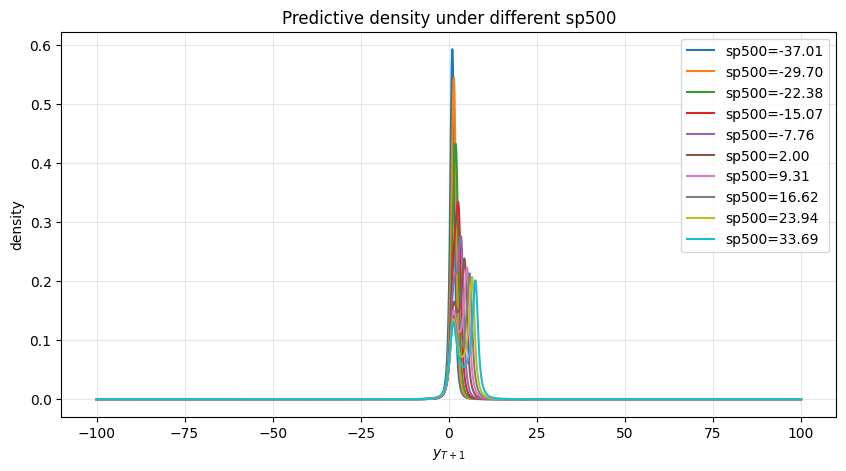

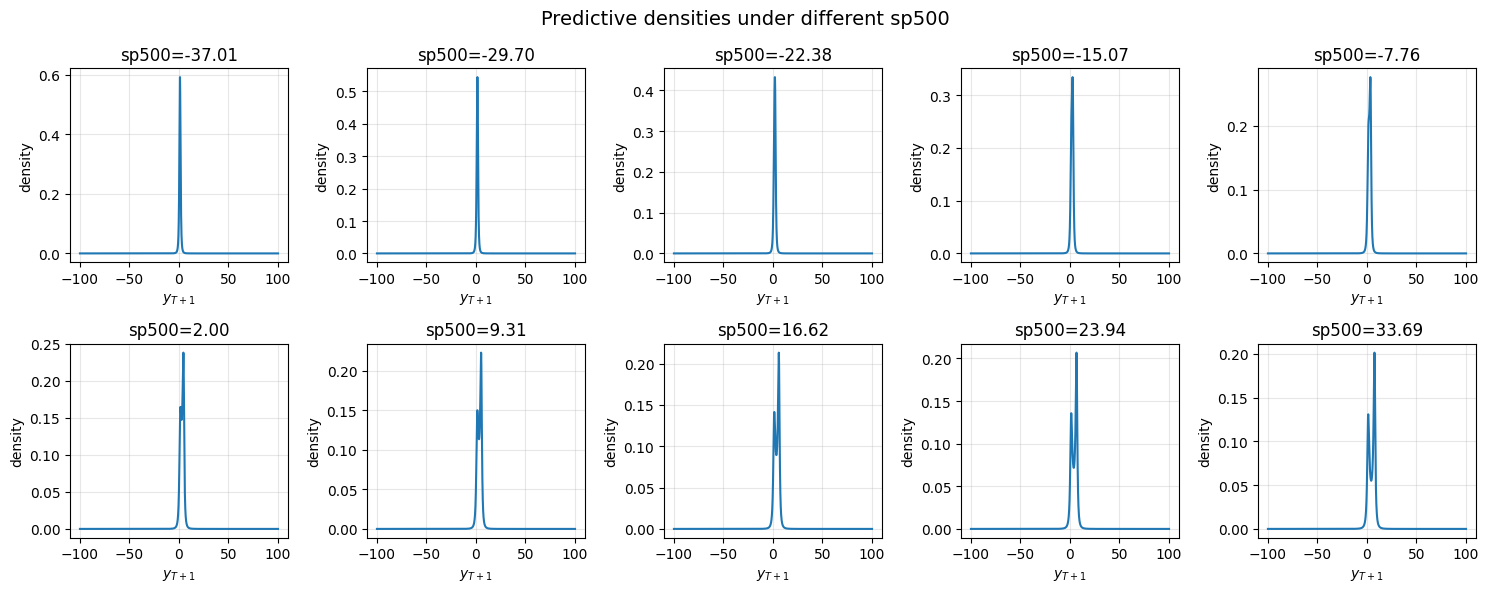

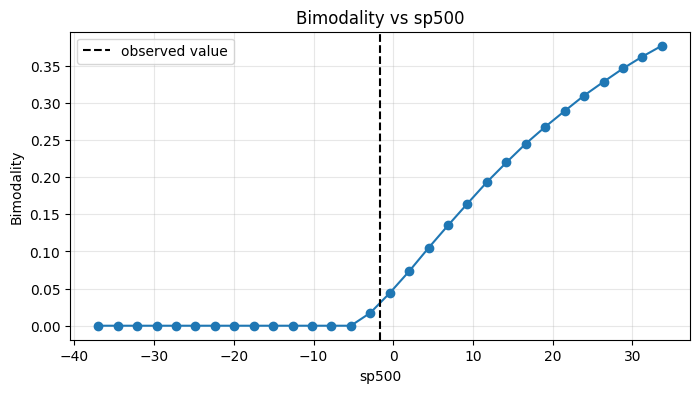

In [34]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_cauchy_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    prominence_factor=prominence
)


----
## MAR(1,1) with Student-t innovations

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -540.0790108400988

Estimated parameters:
phi             =     0.8389 (0.0346)
psi             =     0.3204 (0.0596)
sigma           =     0.8781 (0.0610)
nu              =     3.9976 (0.9279)

Hessian condition number:
1276.5011383178996

Eigenvalues of Hessian:
[1.47947394e+03 5.11270800e+02 2.48022821e+02 1.15900715e+00]

MLE diagnostics

--- MAR model diagnostics ---
Log-likelihood: -540.079011
AIC:            1088.158022
BIC:            1103.566832
R^2:            0.873775

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statistic = 3.403919, p-value = 0.0650417
    lag  5: statistic = 9.778976, p-value = 0.0817457
    lag 10: statistic = 16.917279, p-value = 0.0762145
    lag 20: statistic = 26.161013, p-value = 0.16056

Autocorrelation tests (squared standardized residuals):
  n       = 348
  Ljung-Box (H0: no autocorrelation up to lag h):
    lag  1: statist

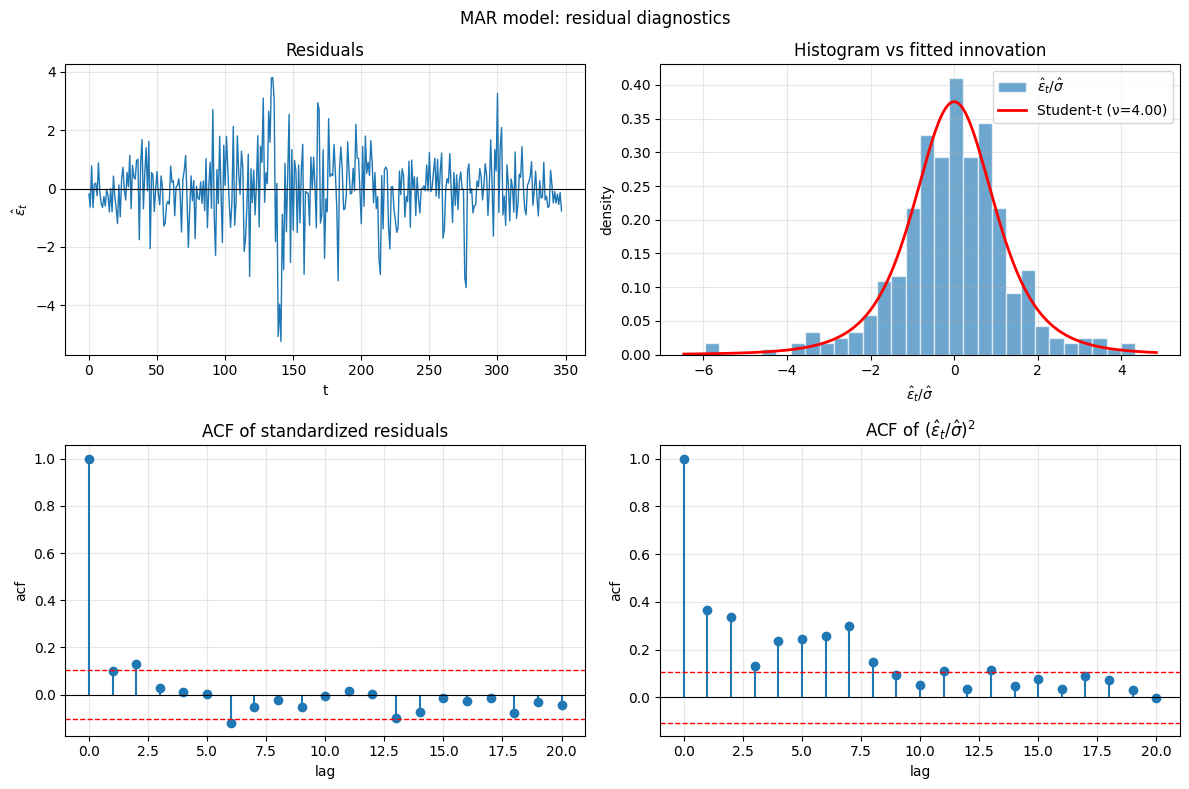

In [35]:
#MLE student-t

param_names = [ "phi", "psi", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_mar,
    param_names=param_names,
    bounds=bounds,
    y=y
)

params = result["params"]

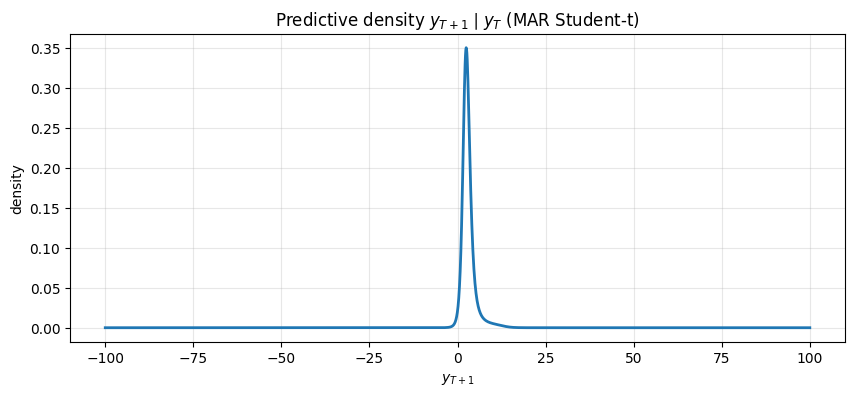

In [36]:
dens = plot_predictive_density(
    predictive_density_fn=mar_studentt_pred_density,
    grid=grid,
    y=y,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T$ (MAR Student-t)")

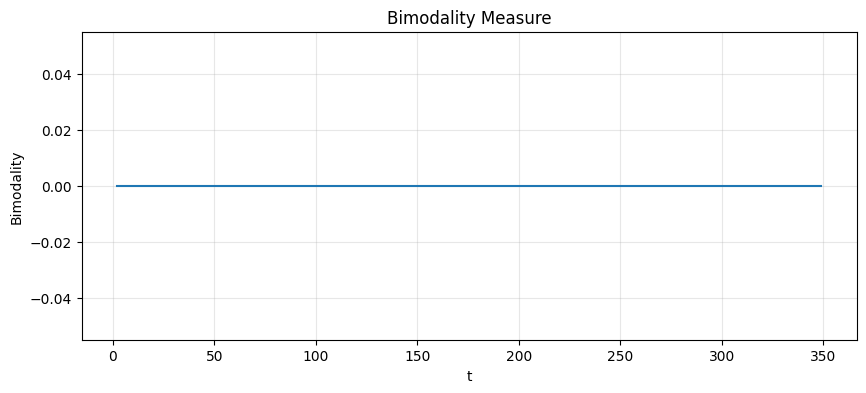

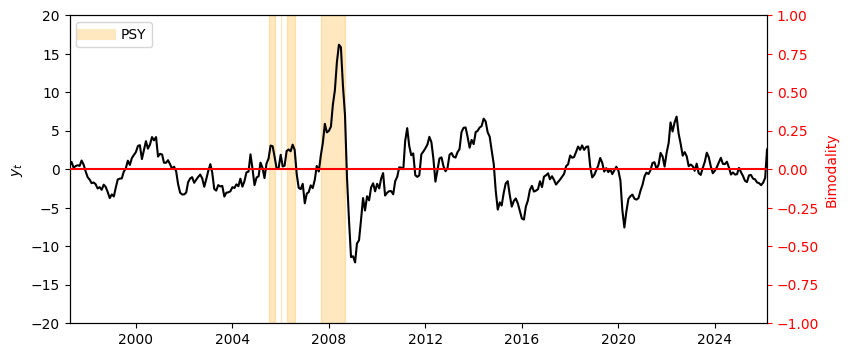

In [37]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=mar_studentt_pred_density,
    y=y,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


----
## MARX(1,1,3) with Student-t Innovations 

### Log-likelihood function

$$
L_T(\phi,\psi,\beta,\sigma,\nu)
=
\sum_{t=2}^{T-1}
\left[
\log \Gamma\left(\frac{\nu+1}{2}\right)
-
\log \Gamma\left(\frac{\nu}{2}\right)
-
\frac{1}{2}\log(\nu\pi)
-
\log \sigma
-
\frac{\nu+1}{2}
\log\left(
1+\frac{1}{\nu}\left(
\frac{
(1+\phi\psi)y_t
-
\phi y_{t-1}
-
\psi y_{t+1}
-
\beta X_t
}{\sigma}
\right)^2
\right)
\right].
$$

Optimization success: True
Log-likelihood: -502.8344438629765

Estimated parameters:
phi             =     0.4173 (0.0628)
psi             =     0.5953 (0.0504)
beta_sp500      =    -0.0497 (0.0205)
beta_vix        =    -0.0937 (0.0425)
beta_indpro     =     0.0794 (0.0168)
beta_ngas_cycle =     0.1065 (0.0274)
beta_treasury_10y =     0.0837 (0.0249)
beta_world_oil_cycle =    -0.1001 (0.0211)
beta_crudeoil_inventory =    -0.1092 (0.0262)
sigma           =     0.8067 (0.0558)
nu              =     4.3530 (1.0901)

Hessian condition number:
16672.04617517154

Eigenvalues of Hessian:
[1.40117577e+04 4.65792698e+03 2.49543820e+03 2.07973295e+03
 1.65621235e+03 1.59650278e+02 8.40434196e-01 1.16608290e+03
 9.48720452e+02 6.84102807e+02 6.21715373e+02]

MLE diagnostics

--- MARX model diagnostics ---
Log-likelihood: -502.834444
AIC:            1027.668888
BIC:            1070.043115
R^2:            0.898741

Autocorrelation tests (standardized residuals):
  n       = 348
  Ljung-Box (H0: no 

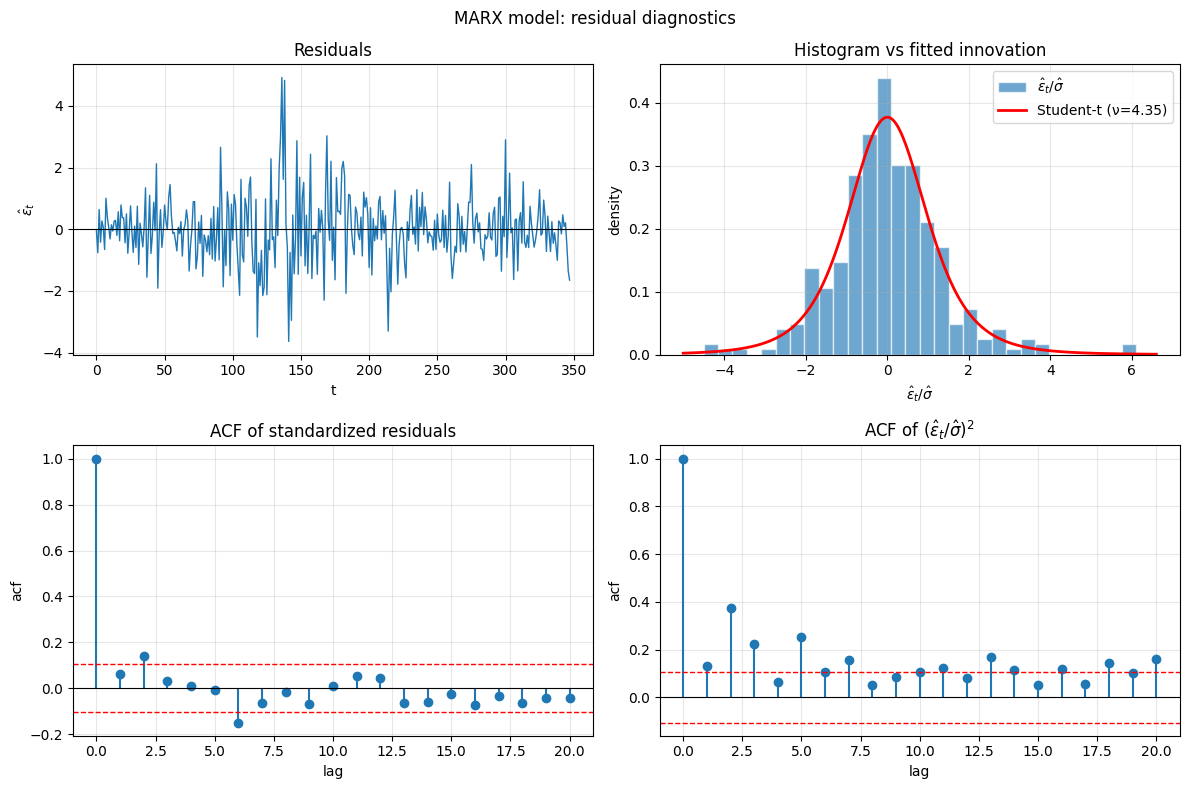

In [38]:
param_names = [ "phi", "psi", "beta_sp500", "beta_vix", "beta_indpro", "beta_ngas_cycle", "beta_treasury_10y","beta_world_oil_cycle", "beta_crudeoil_inventory", "sigma", "nu"]

# Bounds
bounds = [
    (-0.99, 0.99),
    (-0.99, 0.99),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (None, None),
    (1e-6, None),
    (2.01, None)
]

result = run_multistart(
    neg_loglik=neg_loglik_student_marx,
    param_names=param_names,
    bounds=bounds,
    y=y,
    X=X
)

params = result["params"]


### Sample-Based Predictive Density

$$
\hat l(u_{T+1}\mid u_T, X_T)
=
g(u_T-\psi u_{T+1} - \beta X_T)
\,
\frac{
\sum_{t=1}^{T} g(u_{T+1}-\psi u_t - \beta X_{T+1})
}{
\sum_{t=1}^{T} g(u_T-\psi u_t - \beta X_T)
}
$$

$$
g(e)
=
\frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}
{\Gamma\!\left(\frac{\nu}{2}\right)\sqrt{\nu\pi}\,\sigma}
\left(
1+\frac{e^2}{\nu\sigma^2}
\right)^{-\frac{\nu+1}{2}}
$$

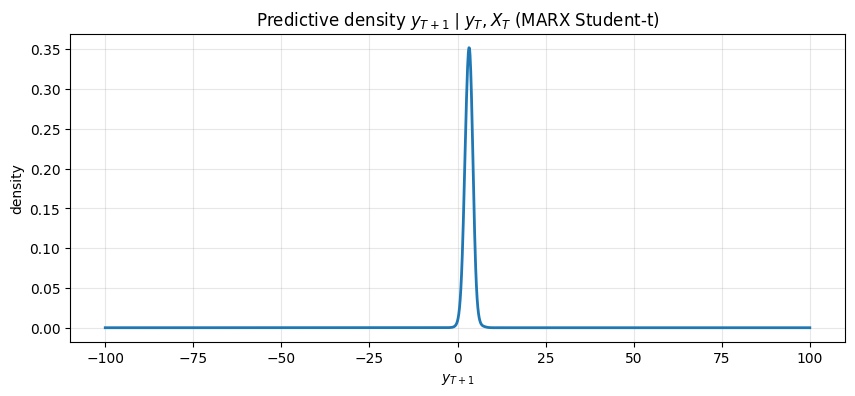

In [39]:
dens = plot_predictive_density(
    predictive_density_fn=marx_studentt_pred_density,
    grid=grid,
    y=y,
    X=X,
    t=t1,
    params=params,
    title=r"Predictive density $y_{T+1} \mid y_T, X_T$ (MARX Student-t)")

### Bimodality

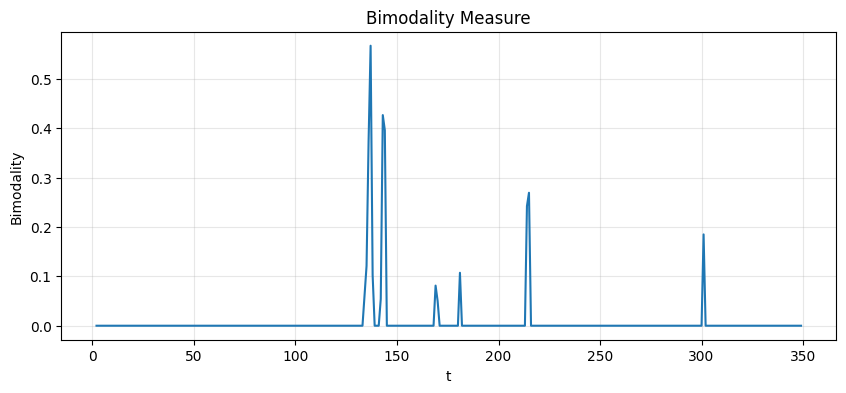

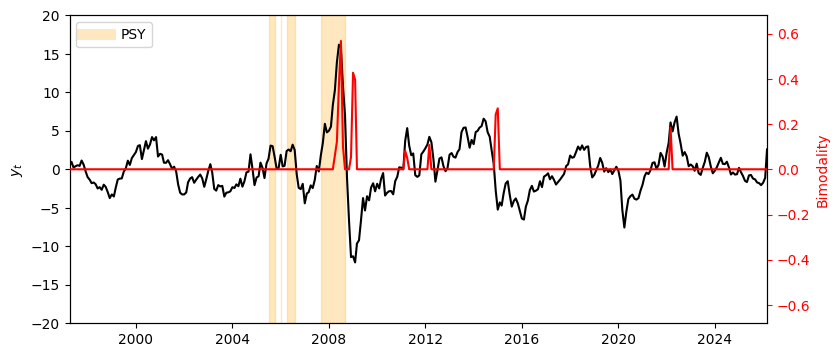

In [40]:
# Get bimodality from min_t to max_t
bimodality_series = compute_bimodality_series(
    times,
    predictive_density_fn=marx_studentt_pred_density,
    y=y,
    X=X,
    params=params,
    grid= grid,
    prominence_factor=prominence
)

# PLOTS
plot_bimodality(times, bimodality_series)

plot_bimodality_and_series(
    df.index[min_t:],
    y[min_t:],
    bimodality_series,
    y_limits=y_limits,
    psy=psy
)


### Bimodality/ Predictive Density changes for different X values

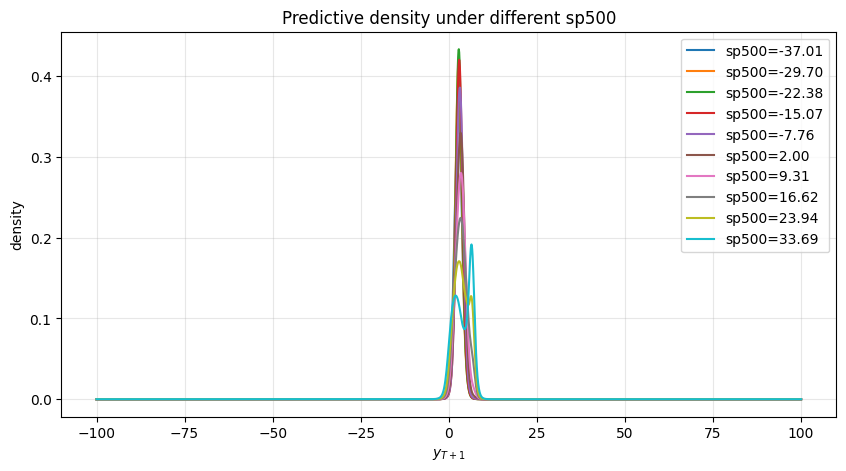

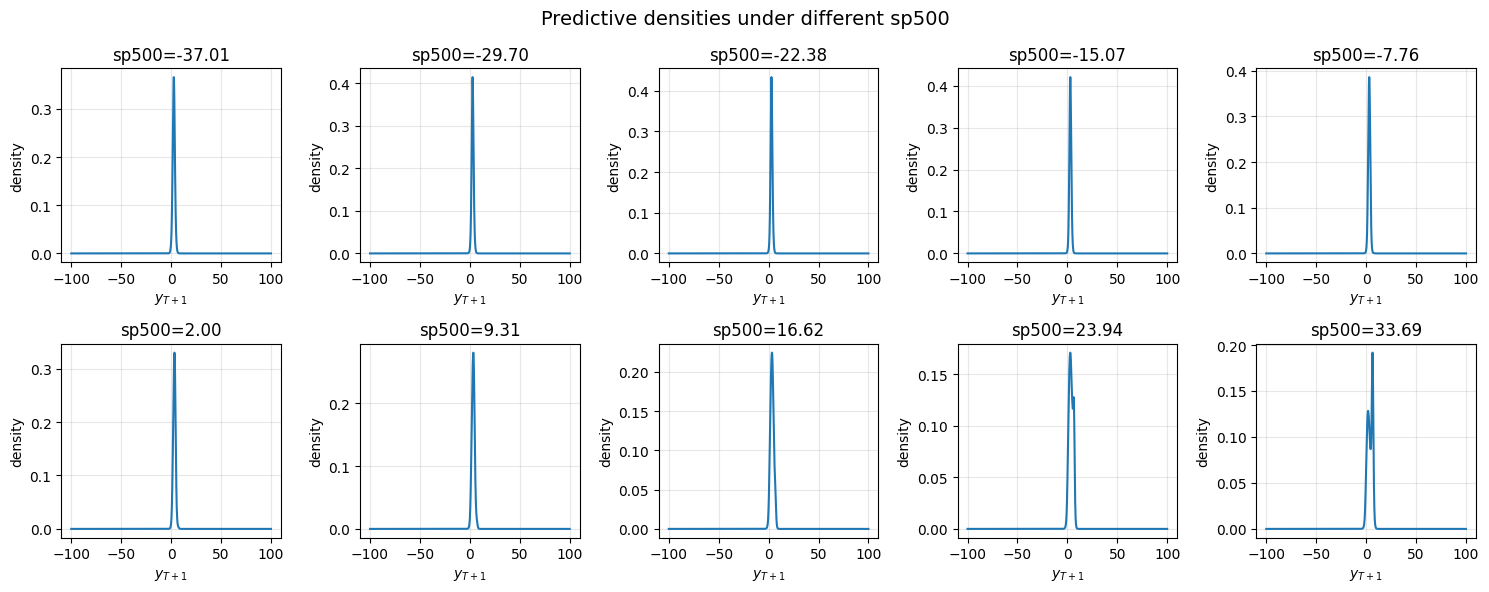

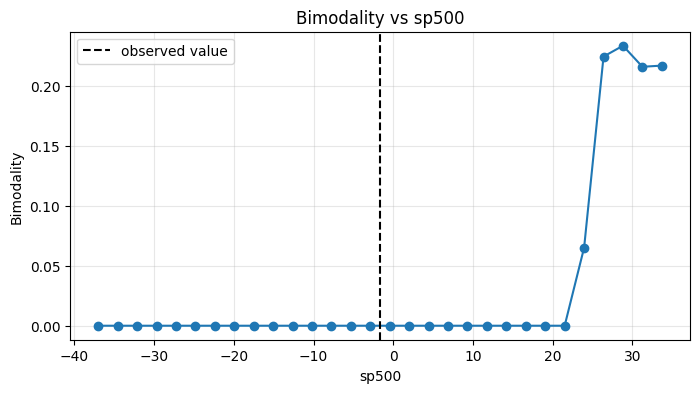

In [41]:
res = shock_analysis(
    var_idx=0,
    X=X,
    y=y,
    params=params,
    predictive_density_fn=marx_studentt_pred_density,
    grid_y=grid,
    n_std=std,
    n_values=values,
    var_names=var,
    prominence_factor=prominence
)
